# PLACE: task-agnostic experiments

In the main experiments, PLACE learns one concept bank per class. Here a single bank is learned from
unlabeled images of several classes (Section 4.4 of the paper): the 10 ImageNet classes (cassette
player, chainsaw, church, English springer, French horn, garbage truck, gas pump, golf ball,
parachute, tench) form one pool, and the 5 COCO classes (hot dog, teddy bear, train, umbrella,
zebra) another, with 200 images per class. Each bank has 100 concepts.

Methods compared, on DINOv2 ViT-B/14 and ViT-MAE ViT-B/16, with 20 seeds each:

| Name in the code | Method | Labels |
|------------------|--------|--------|
| `recon` | PLACE (reconstruction) | no |
| `gram` | PLACE (+Gram) | no |
| `kl` | PLACE (+KL) | yes, reference only |
| `vanilla` | SAE | no |
| `gated` | Gated SAE | no |

Outputs:

| Notebook | Paper |
|----------|-------|
| Table R1: MSE, C-Gini, d_KL, Gram error | Table 32 (Appendix E.14) |
| Table R2: recon vs +Gram, agreement with +KL | Table 3 (Section 4.4) |
| Table R3: W-Stab | Table 33 (Appendix E.14) |
| Section F: concept heatmaps | n/a |

With `RUN_TRAINING = False` (default) the saved banks in `results/banks/` are loaded and only the
evaluation, statistics and figures are recomputed. `RUN_TRAINING = True` retrains all banks.

## 1. Imports

SciPy is used for the Wilcoxon test and the Hungarian matching, scikit-learn for the regressions
behind CMCS.

In [1]:
import os, re, json, glob, math, time, random, warnings, subprocess, csv
from math import ceil
from datetime import datetime
from pathlib import Path
from typing import Optional
from dataclasses import dataclass

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.linalg import svd
from torchvision import transforms
import timm
from tqdm.auto import tqdm

import matplotlib.pyplot as plt
from IPython.display import Image, display

# SciPy: Wilcoxon signed-rank test (significance) and Hungarian matching (concept alignment).
from scipy.stats import wilcoxon, pearsonr, spearmanr
from scipy.stats._warnings_errors import ConstantInputWarning
from scipy.optimize import linear_sum_assignment

# scikit-learn: the regressors behind the cross-model CMCS metric.
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import LinearSVR, SVR
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import r2_score
from sklearn.utils._testing import ignore_warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore")          # keep the notebook output readable
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Configuration

Flags:

- `RUN_TRAINING`: retrain all banks (`True`) or load the saved ones (`False`).
- `RUN_SAE`: include the SAE baselines.
- `FORCE_EVAL`: recompute the Section B evaluation even if the cached CSV covers every bank.
- `WRITE_TABLES_MD`: also write the tables to a markdown file.
- `N_BOOT`: bootstrap resamples for the confidence intervals in Section E.

The remaining settings are those used to train the saved banks: the hyperparameters of Table 6 in
the paper, except rank 100 and 5,500 steps for the +KL bank. The image pool is fixed (200 images per
class, `POOL_SEED = 0`); the seed (42 to 61) changes the initialization and the random subsampling
during training. Images are center-cropped to 224×224, giving 64 tokens per image for DINOv2 and 49
for ViT-MAE after 2×2 grouping.

Paths are resolved next to the notebook first, then in a parent repository. The last line prints
`self-contained : True` when all inputs are in this folder.

In [2]:
# --- Execution flags ---------------------------------------------------------
RUN_TRAINING = False      # True: re-extract tokens and refit the whole grid (slow, needs the data)
RUN_SAE      = True       # include the SAE baselines (vanilla and gated)
FORCE_EVAL   = False       # True: recompute the cross-eval even if the cached CSV already covers every bank
WRITE_TABLES_MD = False   # True: also write the final tables (R1 to R3) to a markdown file
N_BOOT       = 10000      # bootstrap resamples for the confidence interval in _paired_test

# --- Experiment grid ---------------------------------------------------------
BACKBONES = [("dinov2", "dinov2_vitb14"), ("mae", "vit_base_patch16_224.mae")]
SOURCES   = ["imagenet", "coco"]
VARIANT   = "unfiltered"          # pooled, label-free: no class filtering of the images

EXTRACT_LAYER        = 9          # ViT block at which patch tokens are read
GROUP_SIZE           = 2          # 2x2 spatial pooling of the token grid before factorisation
RANK                 = 100        # number of concepts in the shared bank
N_SEEDS              = 20         # random restarts per condition (drives the significance tests)
SEED_START           = 42
MAX_IMAGES_PER_CLASS = 200        # images sampled per class into the pooled set
POOL_SEED            = 0          # RNG seed for that sampling; fixed so the pool is deterministic

# --- NMF (PatchNMF) hyperparameters ------------------------------------------
STEPS       = 22000       # optimisation steps for the recon and +Gram banks
KL_STEPS    = 5500        # the +KL bank converges faster, so it uses fewer steps
LR          = 5e-4
LAMBDA_VAL  = 1.0         # weight of the active faithfulness term (Gram or KL)
GRAM_LAMBDA = 1.0
EPSILON     = 1e-6        # early-stopping tolerance on the total loss
L1_U        = 1e-6        # L1 on the coefficients U (encourages concept sparsity)
L2_W        = 1e-6        # L2 on the dictionary W
NNDSVD      = 80.0        # NNDSVD init on this percentage of subsampled rows
NMF_TYPE    = "Semi-NMF"  # mixed-sign dictionary, non-negative coefficients
BATCH_SIZE  = 4

# --- SAE baseline hyperparameters --------------------------------------------
SAE_VARIANTS = ["vanilla", "gated"]
SAE_LR       = 1e-3
L1_COEF      = 1e-3
TOPK_K       = 8
TOKEN_BATCH  = 4096

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Preprocessing applied to every image before it enters a backbone.
PREPROCESS = {"resize": 256, "center_crop": 224,
              "normalize_mean": [0.485, 0.456, 0.406],
              "normalize_std":  [0.229, 0.224, 0.225]}

# --- Paths: prefer the local copies, fall back to the parent repo ------------
LOCAL = Path.cwd()

def _find_repo_root():
    """Return the first ancestor that looks like the repo, or LOCAL if there is none.

    When the notebook is used on its own, every path below falls back to LOCAL,
    which then holds all the inputs.
    """
    for cand in [LOCAL, *LOCAL.parents]:
        if (cand / "results" / "banks").exists() or (cand / "src" / "conceptextraction").exists():
            return cand
    return LOCAL

def _first_existing(*cands):
    """First path that exists, else the last candidate (so messages stay informative)."""
    return next((c for c in cands if c.exists()), cands[-1])

REPO_ROOT = _find_repo_root()

DATA_DIR      = _first_existing(LOCAL / "data", REPO_ROOT / "data")
BANKS_DIR     = _first_existing(LOCAL / "results" / "banks", REPO_ROOT / "results" / "banks")
EVAL_CSV      = _first_existing(LOCAL / "results" / "agnostic" / "bank_faithfulness_eval.csv",
                                REPO_ROOT / "results" / "agnostic" / "bank_faithfulness_eval.csv")
# The head loader joins relative paths like "models/coco/vfm/...", so
# MODELS_PARENT is the directory that contains `models/`.
MODELS_PARENT = LOCAL if (LOCAL / "models" / "coco" / "vfm").exists() else REPO_ROOT
OUT_DIR       = Path("./output"); OUT_DIR.mkdir(exist_ok=True)

_self_contained = all(p == LOCAL or LOCAL in p.parents for p in
                      [DATA_DIR, BANKS_DIR, EVAL_CSV.parent, MODELS_PARENT])
print(f"Repo root      : {REPO_ROOT}")
print(f"Device         : {DEVICE}")
print(f"Data dir       : {DATA_DIR}")
print(f"Banks dir      : {BANKS_DIR}  (exists={BANKS_DIR.exists()})")
print(f"Eval CSV       : {EVAL_CSV}  (exists={EVAL_CSV.exists()})")
print(f"Models parent  : {MODELS_PARENT}")
print(f"self-contained : {_self_contained}  (all inputs resolve under {LOCAL})")

Repo root      : .
Device         : cuda
Data dir       : ./data
Banks dir      : ./results/banks  (exists=True)
Eval CSV       : ./results/agnostic/bank_faithfulness_eval.csv  (exists=True)
Models parent  : .
self-contained : True  (all inputs resolve under .)


## 3. Core code

- `ViTLayerSplit`: splits a frozen ViT after `EXTRACT_LAYER`; returns the patch tokens and can run
  tokens through the remaining blocks and a classifier head (needed for the +KL bank and d_KL).
- `load_vfm`: loads DINOv2 from torch hub or ViT-MAE from timm.
- `PatchNMF`: PLACE (Semi-NMF on patch tokens, with optional Gram or KL term).
- SAE baselines with the same interface as `PatchNMF`. Vanilla and gated SAEs are reported; TopK and
  archetypal SAEs are defined but not used.
- Bank saving and loading: each bank is an `.npz` with $U$, $W$, the per-image concept signature
  (mean of $U$ over the tokens of each image), the concept importances, the loss curves and metadata,
  indexed by `manifest_*.csv`. Token sets are cached.
- Statistics: Wilcoxon test, bootstrap confidence intervals, Holm correction, Hungarian-matched
  cosine similarity.
- Agreement metrics: MCS, CMCS and C-Gini.
- Data helpers: class files, pooled datasets, and backbone loading with the classifier head for each
  dataset (DINOv2 linear head from torch hub and the fine-tuned MAE classifier on ImageNet, linear
  probes on COCO, see Appendix D.1).
- Heatmap plotting.

In [3]:
# ==========================================================================
# ViTLayerSplit: split a frozen ViT into feature extractor and head
# ==========================================================================
class ViTLayerSplit(nn.Module):
    """
    Splits a timm, torchvision, or torch.hub ViT into feature extractor (g)
    and head (h).

    Supported backbones:
        - timm ViT (has ``blocks`` + ``_pos_embed`` method)
        - torchvision ViT (has ``encoder.layers``)
        - torch.hub DINOv1/v2/v3 (has ``blocks`` + ``prepare_tokens*`` method)

    Parameters
    ----------
    head : nn.Module, optional
        External classification head (e.g. a linear probe).  When provided it
        is used in ``classify_from_tokens`` instead of the model's own head.
        Required for hub VFMs which have no built-in classifier.
    """
    def __init__(self, vit_model, split_layer=11, group_size=1, head=None,
                 lc_layers=None):
        """
        Parameters
        ----------
        lc_layers : int or None
            Set to the number of last blocks used by DINOv2 _lc heads (1 or 4).
            When set, classify_from_tokens builds the multi-block concatenated
            input that DINOv2's linear heads expect:
              cat(CLS_last_n_blocks..., avg_patches_from_last_block)
            Leave None for simple single-CLS-token heads.
        """
        super().__init__()
        self.vit = vit_model
        self.split_layer = split_layer
        self.head = head  # optional external classifier (e.g. linear probe)
        self._lc_layers = lc_layers  # DINOv2 _lc multi-block head config

        # ── Architecture detection ──────────────────────────────────────────
        # timm: has both `blocks` and `_pos_embed` (a method)
        # torchvision: has `encoder.layers`
        # hub (DINOv1/v2/v3): has `blocks` and `prepare_tokens*`, no `_pos_embed`
        self.is_timm = hasattr(vit_model, 'blocks') and hasattr(vit_model, '_pos_embed')
        self.is_torchvision = not self.is_timm and hasattr(vit_model, 'encoder') and hasattr(vit_model.encoder, 'layers')
        self.is_hub = not self.is_timm and not self.is_torchvision and hasattr(vit_model, 'blocks')

        # Register tokens (DINOv2 with registers)
        self._n_register_tokens = getattr(vit_model, 'num_register_tokens', 0)

        self.hidden_dim = getattr(vit_model, 'embed_dim', getattr(vit_model, 'num_features', getattr(vit_model, 'hidden_dim', 768)))

        if hasattr(vit_model, 'patch_embed') and hasattr(vit_model.patch_embed, 'patch_size'):
            ps = vit_model.patch_embed.patch_size
            self.patch_pixel_size = ps[0] if isinstance(ps, tuple) else ps
        elif hasattr(vit_model, 'patch_size'):
            self.patch_pixel_size = vit_model.patch_size
        else:
            self.patch_pixel_size = 16

        self.grid_size = 224 // self.patch_pixel_size
        self.n_patches = self.grid_size ** 2

        if self.is_timm or self.is_hub:
            self.n_blocks = len(self.vit.blocks)
        else:
            self.n_blocks = len(self.vit.encoder.layers)

        self.group_size = group_size
        self.grouped_grid_size = self.grid_size // group_size
        self.n_patches_grouped = self.grouped_grid_size ** 2
        self.group_pixel_size = self.patch_pixel_size * group_size

        if not (0 <= split_layer < self.n_blocks):
            raise ValueError(
                f"split_layer must be in [0, {self.n_blocks - 1}], "
                f"got {split_layer}"
            )

        if self.grid_size % group_size != 0:
            effective = self.grouped_grid_size * group_size
            dropped = self.grid_size - effective
            print(f"  WARNING: grid_size {self.grid_size} not divisible by "
                  f"group_size {group_size}. Dropping {dropped} edge "
                  f"token(s) per side ({self.grid_size}->{effective}).")

    def _prepare_tokens(self, x):
        if x.shape[2] != 224 or x.shape[3] != 224:
            x = F.interpolate(x, size=(224, 224), mode='bilinear', align_corners=False)

        if self.is_timm:
            x = self.vit.patch_embed(x)
            x = self.vit._pos_embed(x)
            x = self.vit.norm_pre(x) if hasattr(self.vit, 'norm_pre') and self.vit.norm_pre is not None else x
            if hasattr(self.vit, 'patch_drop') and getattr(self.vit, 'patch_drop') is not None:
                x = self.vit.patch_drop(x)
        elif self.is_hub:
            # DINOv1/v2/v3: use their own token preparation method
            if hasattr(self.vit, 'prepare_tokens_with_masks'):
                x = self.vit.prepare_tokens_with_masks(x, masks=None)
            elif hasattr(self.vit, 'prepare_tokens'):
                x = self.vit.prepare_tokens(x)
            else:
                # Manual fallback: patch_embed + CLS + pos_embed
                B, C, H, W = x.shape
                x = self.vit.patch_embed(x)
                cls = self.vit.cls_token.expand(B, -1, -1)
                x = torch.cat([cls, x], dim=1)
                if hasattr(self.vit, 'interpolate_pos_encoding'):
                    x = x + self.vit.interpolate_pos_encoding(x, H, W)
                else:
                    x = x + self.vit.pos_embed
        else:
            # torchvision
            x = self.vit._process_input(x)
            n = x.shape[0]
            cls = self.vit.class_token.expand(n, -1, -1)
            x = torch.cat([cls, x], dim=1)
            x = x + self.vit.encoder.pos_embedding
            x = self.vit.encoder.dropout(x)

        return x

    def group_tokens(self, patch_tokens):
        if self.group_size == 1:
            return patch_tokens

        B, N, D = patch_tokens.shape
        g = self.grid_size

        spatial = patch_tokens.reshape(B, g, g, D).permute(0, 3, 1, 2)
        pooled = F.avg_pool2d(spatial, kernel_size=self.group_size,
                              stride=self.group_size)

        grouped = pooled.flatten(2).permute(0, 2, 1)
        return grouped

    def ungroup_tokens(self, grouped_tokens):
        if self.group_size == 1:
            return grouped_tokens

        B, N_g, D = grouped_tokens.shape
        gg = self.grouped_grid_size
        g = self.grid_size
        gs = self.group_size

        spatial = grouped_tokens.reshape(B, gg, gg, D).permute(0, 3, 1, 2)
        expanded = spatial.repeat_interleave(gs, dim=2).repeat_interleave(gs, dim=3)

        if expanded.shape[2] != g or expanded.shape[3] != g:
            padded = torch.zeros(B, D, g, g, device=expanded.device, dtype=expanded.dtype)
            h_e, w_e = expanded.shape[2], expanded.shape[3]
            padded[:, :, :h_e, :w_e] = expanded
            expanded = padded

        return expanded.flatten(2).permute(0, 2, 1)

    def extract_patch_tokens(self, x):
        x = self._prepare_tokens(x)

        if self.is_timm or self.is_hub:
            for i, block in enumerate(self.vit.blocks):
                x = block(x)
                if i == self.split_layer:
                    break
        else:
            for i, block in enumerate(self.vit.encoder.layers):
                x = block(x)
                if i == self.split_layer:
                    break

        # CLS is index 0; skip register tokens (indices 1..n_reg) for hub models
        cls_L = x[:, 0, :]
        patch_start = 1 + self._n_register_tokens
        raw_patches = x[:, patch_start:, :]

        grouped = self.group_tokens(raw_patches)
        return cls_L, grouped

    def classify_from_tokens(self, cls_L, patch_tokens_grouped):
        patch_tokens_full = self.ungroup_tokens(patch_tokens_grouped)

        if self.is_hub:
            # Re-insert zero register tokens so remaining blocks see the right shape
            B = cls_L.shape[0]
            if self._n_register_tokens > 0:
                reg = torch.zeros(B, self._n_register_tokens, self.hidden_dim,
                                  device=cls_L.device, dtype=cls_L.dtype)
                x = torch.cat([cls_L.unsqueeze(1), reg, patch_tokens_full], dim=1)
            else:
                x = torch.cat([cls_L.unsqueeze(1), patch_tokens_full], dim=1)

            # Run remaining blocks, collecting every output for multi-block heads
            remaining_outputs = []
            for i, block in enumerate(self.vit.blocks):
                if i <= self.split_layer:
                    continue
                x = block(x)
                remaining_outputs.append(x)

            if self.head is None:
                raise ValueError(
                    "Hub VFM has no classifier head. Pass head= to ViTLayerSplit."
                )

            norm_fn = (self.vit.norm if hasattr(self.vit, 'norm')
                       and self.vit.norm is not None else nn.Identity())
            patch_start = 1 + self._n_register_tokens

            if self._lc_layers is not None:
                # DINOv2 _lc head: plain nn.Linear that expects a concatenation of
                # CLS tokens from the last _lc_layers blocks + avg patch tokens
                # from the final block, the same input DINOv2 builds for these heads.
                n = self._lc_layers
                available = len(remaining_outputs)
                if available < n:
                    # Fewer remaining blocks than the head needs. Repeat the last
                    # available output to reach the required count. Both the original
                    # and reconstructed logit paths use this same approximation, so
                    # KL faithfulness remains consistent. Set split_layer <=
                    # (n_blocks - lc_layers) to avoid this padding.
                    import warnings as _w
                    _w.warn(
                        f"_lc head needs {n} blocks but only {available} remain after "
                        f"split_layer={self.split_layer}. Padding by repeating the last "
                        f"block output. Set split_layer <= {self.n_blocks - n} to avoid this.",
                        stacklevel=3,
                    )
                    pad = [remaining_outputs[-1]] * (n - available)
                    last_n = pad + remaining_outputs
                else:
                    last_n = remaining_outputs[-n:]

                normed = [norm_fn(out) for out in last_n]
                cls_tokens  = [out[:, 0] for out in normed]
                avg_patches = normed[-1][:, patch_start:].mean(dim=1)
                linear_input = torch.cat(cls_tokens + [avg_patches], dim=1)
                return self.head(linear_input)
            else:
                # Simple head (custom probe / plain nn.Linear): just CLS token
                final_x = norm_fn(remaining_outputs[-1])
                return self.head(final_x[:, 0])

        x = torch.cat([cls_L.unsqueeze(1), patch_tokens_full], dim=1)

        if self.is_timm:
            for i, block in enumerate(self.vit.blocks):
                if i <= self.split_layer:
                    continue
                x = block(x)

            if hasattr(self.vit, 'norm') and self.vit.norm is not None:
                x = self.vit.norm(x)

            cls_final = x[:, 0]
            if self.head is not None:
                return self.head(cls_final)
            if hasattr(self.vit, 'forward_head'):
                return self.vit.forward_head(x)
            if hasattr(self.vit, 'head'):
                return self.vit.head(cls_final)
            return self.vit.get_classifier()(cls_final)
        else:
            for i, block in enumerate(self.vit.encoder.layers):
                if i <= self.split_layer:
                    continue
                x = block(x)

            x = self.vit.encoder.ln(x)
            cls_final = x[:, 0]
            if self.head is not None:
                return self.head(cls_final)
            if hasattr(self.vit, 'heads'):
                return self.vit.heads(cls_final)
            return self.vit.head(cls_final)

    def forward(self, x):
        if x.shape[2] != 224 or x.shape[3] != 224:
            x = F.interpolate(x, size=(224, 224), mode='bilinear', align_corners=False)
        return self.vit(x)

    def token_to_pixel(self, group_index):
        gg = self.grouped_grid_size
        row = group_index // gg
        col = group_index % gg
        return col * self.group_pixel_size, row * self.group_pixel_size

In [4]:
# ==========================================================================
# load_vfm: load a vision foundation model (DINO family or ViT-MAE)
# ==========================================================================
def load_vfm(model_family: str, model_name: str) -> nn.Module:
    """
    Load a Vision Foundation Model by family and name.

    Parameters
    ----------
    model_family : str
        One of 'dino', 'dinov2', 'dinov3', 'mae'.
    model_name : str
        Model identifier, e.g. 'dino_vitb16', 'dinov2_vitb14', 'dinov3_vitb16',
        'vit_base_patch16_224.mae'.

    Returns
    -------
    nn.Module
        The loaded VFM in eval mode.
    """
    family = model_family.lower()

    if family == 'dino':
        model = torch.hub.load('facebookresearch/dino', model_name)
    elif family == 'dinov2':
        model = torch.hub.load('facebookresearch/dinov2', model_name)
    elif family == 'dinov3':
        import os
        from pathlib import Path
        # Check models/ for local weights first (avoids HTTP 403 on fbaipublicfiles.com)
        local_weights_candidates = [
            Path.cwd() / "models" / f"{model_name}_pretrain_lvd1689m*.pth",
        ]
        local_weights = None
        for pattern in local_weights_candidates:
            import glob as _glob
            matches = _glob.glob(str(pattern))
            if matches:
                local_weights = str(Path(matches[0]).resolve())
                break
        if local_weights:
            print(f"  Loading dinov3 weights from local file: {local_weights}")
            model = torch.hub.load('facebookresearch/dinov3', model_name,
                                   weights=local_weights)
        else:
            model = torch.hub.load('facebookresearch/dinov3', model_name)
    elif family == 'mae':
        import timm
        model = timm.create_model(model_name, pretrained=True)
    elif family == 'vit':
        # Generic timm ViT (e.g. vit_base_patch16_224.augreg_in21k_ft_in1k).
        # Comes with a fine-tuned 1000-class CLS-based head, unlike MAE.
        import timm
        model = timm.create_model(model_name, pretrained=True)
    else:
        raise ValueError(
            f"Unknown model_family '{model_family}'. "
            f"Expected one of: 'dino', 'dinov2', 'dinov3', 'mae', 'vit'."
        )

    model.eval()
    return model

In [5]:
# ==========================================================================
# PatchNMF: Semi-NMF on patch tokens with optional KL / Gram faithfulness
# ==========================================================================
class PatchNMF:
    """
    NMF on ViT native patch tokens with optional KL faithfulness.

    Parameters
    ----------
    model : ViTLayerSplit
        Layer-split ViT model.
    rank : int
        Number of concepts.
    steps : int
        Max optimization steps.
    learning_rate : float
        Adam learning rate.
    lambda_val : float
        Weight of KL term (ignored if use_kl=False).
    epsilon : float
        Convergence threshold.
    batch_size : int
        Batch size for inference.
    device : str or torch.device
    use_kl : bool
        If True, add the KL faithfulness term.
        If False, reconstruction only.
    nmf_type : str
        'NMF' or 'Semi-NMF'.
    target_class : int
        Target class for KL faithfulness and importance estimation.
    """

    def __init__(self, model, rank=25, steps=22000, learning_rate=5e-4,
                 lambda_val=1.0, epsilon=1e-3, batch_size=4,
                 device=None, use_kl=True, nmf_type='Semi-NMF',
                 target_class=497, l1_u=0.0, l2_w=0.0, nndsvd=100.0,
                 use_geo=False, use_gram=False, geo_tau=1.0, gram_lambda=1.0,
                 preprocess_cfg=None, convergence_callback=None):
        self.model = model.eval()
        self.rank = rank
        self.steps = steps
        self.learning_rate = learning_rate
        self.lambda_val = lambda_val
        self.epsilon = epsilon
        self.batch_size = batch_size
        self.device = device or ('cuda' if torch.cuda.is_available() else 'cpu')
        self.use_kl = use_kl
        self.nmf_type = nmf_type
        self.target_class = target_class
        self.l1_u = l1_u
        self.l2_w = l2_w
        self.nndsvd = nndsvd
        self.use_geo = use_geo
        self.use_gram = use_gram
        self.geo_tau = geo_tau
        self.gram_lambda = gram_lambda
        self._geo_max_samples = 2048
        self._gram_max_samples = 2048
        self._convergence_cb = convergence_callback

        self.model = self.model.to(self.device)

        pp = preprocess_cfg or {}
        self.transform = transforms.Compose([
            transforms.Resize(pp.get('resize', 256)),
            transforms.CenterCrop(pp.get('center_crop', 224)),
            transforms.ToTensor(),
            transforms.Normalize(mean=pp.get('normalize_mean', [0.485, 0.456, 0.406]),
                                 std=pp.get('normalize_std', [0.229, 0.224, 0.225]))
        ])

    def preprocess_images(self, images_np):
        """Convert numpy images to preprocessed tensors."""
        to_pil = transforms.ToPILImage()
        tensors = [self.transform(to_pil(img)) for img in images_np]
        return torch.stack(tensors, 0).to(self.device)

    def evaluate_accuracy(self, images_preprocessed):
        """Full-model accuracy on target class."""
        preds = self._batch_inference(
            self.model, images_preprocessed
        )
        predicted = torch.argmax(preds, dim=-1)
        return (predicted == self.target_class).float().mean().item()
        
    def filter_correctly_classified(self, images_preprocessed, images_np_ref):
        """
        Runs inference on the images and returns only those correctly 
        classified as self.target_class to prune false negatives.
        Also returns the pruned original `images_np_ref` numpy array 
        so visualization loops don't crash from shape mismatch.
        """
        print("Filtering images to keep only correctly classified ones...")
        preds = self._batch_inference(
            self.model, images_preprocessed
        )
        predicted_classes = torch.argmax(preds, dim=-1)
        
        mask = (predicted_classes == self.target_class)
        kept_images = images_preprocessed[mask]
        
        print(f"Kept {len(kept_images)} / {len(images_preprocessed)} images.")
        
        return kept_images, images_np_ref[mask.cpu().numpy()]

    def _batch_inference(self, fn, dataset, batch_size=None):
        """Run fn in batches, return concatenated results."""
        bs = batch_size or self.batch_size
        n_batches = ceil(len(dataset) / bs)
        results = []
        with torch.no_grad():
            for i in range(n_batches):
                x = dataset[i * bs:(i + 1) * bs].to(self.device)
                results.append(fn(x).cpu())
        return torch.cat(results)

    def extract_all(self, images_preprocessed):
        """
        Extract patch tokens for all images.

        Returns
        -------
        cls_L : Tensor (B, 768)
            CLS tokens at split layer.
        patch_tokens : Tensor (B, 196, 768)
            Patch tokens at split layer.
        """
        bs = self.batch_size
        n_batches = ceil(len(images_preprocessed) / bs)
        all_cls = []
        all_patches = []

        with torch.no_grad():
            for i in tqdm(range(n_batches), desc="Extracting patch tokens"):
                batch = images_preprocessed[i * bs:(i + 1) * bs].to(self.device)
                cls_L, patch_tokens = self.model.extract_patch_tokens(batch)
                all_cls.append(cls_L.cpu())
                all_patches.append(patch_tokens.cpu())

        cls_L = torch.cat(all_cls, dim=0)          # (B, 768)
        patch_tokens = torch.cat(all_patches, dim=0)  # (B, 196, 768)
        return cls_L, patch_tokens

    def nndsvd_initialization(self, A, r):
        """
        NNDSVD initialization for NMF or random initialization if nndsvd <= 0.
        For large matrices, subsample rows to make SVD tractable based on nndsvd.
        """
        # Random initialization if nndsvd <= 0
        if self.nndsvd <= 0:
            print(f"  Random initialization (nndsvd={self.nndsvd})...")
            n_rows, n_cols = A.shape
            U = torch.rand(n_rows, r, dtype=torch.float32, device=A.device)
            W = torch.rand(r, n_cols, dtype=torch.float32, device=A.device)
            return U, W

        n_rows = A.shape[0]
        max_rows = max(1, int(n_rows * self.nndsvd / 100.0))

        if n_rows > max_rows:
            print(f"  Subsampling {max_rows}/{n_rows} rows for NNDSVD init ({self.nndsvd}%)...")
            idx = torch.randperm(n_rows)[:max_rows]
            A_sub = A[idx]
        else:
            A_sub = A

        U_svd, S_svd, V_svd = svd(A_sub, full_matrices=False)
        # W is initialized from V (right singular vectors) — valid for full A
        # U is re-computed for full A using: U_full = A @ W^T @ (W @ W^T)^{-1}
        W = torch.zeros(r, A.shape[1], dtype=torch.float32, device=A.device)
        W[0, :] = torch.sqrt(S_svd[0]) * torch.abs(V_svd[0, :])

        for i in range(1, r):
            v = V_svd[i, :]
            v_pos, v_neg = torch.clamp(v, min=0), torch.clamp(-v, min=0)
            v_norm, vn_norm = torch.norm(v_pos), torch.norm(v_neg)
            if v_norm >= vn_norm:
                W[i, :] = torch.sqrt(S_svd[i]) * v_pos / (v_norm + 1e-10)
            else:
                W[i, :] = torch.sqrt(S_svd[i]) * v_neg / (vn_norm + 1e-10)

        # Compute U for the full A given W: U = A @ W^T @ (W @ W^T)^{-1}
        Wt = W.T  # (768, r)
        WWt_inv = torch.linalg.pinv(W @ Wt)  # (r, r)
        U = A @ Wt @ WWt_inv  # (N, r)
        U = torch.clamp(U, min=0)  # ensure non-negative

        return U, W

    def _compute_sim_loss(self, A, A_hat):
        """
        Distributional similarity faithfulness loss.

        For each row i, build a softmax distribution over pairwise squared
        distances to all other rows (with temperature tau). Minimize the
        mean KL divergence between the distributions from A and A_hat.

        tau is auto-scaled: effective_tau = geo_tau * mean_pairwise_distance²
        so the softmax is well-conditioned regardless of activation magnitude.

        Subsamples rows when n > _geo_max_samples for speed.
        """
        n = A.shape[0]
        if n > self._geo_max_samples:
            idx = torch.randperm(n, device=A.device)[:self._geo_max_samples]
            A = A[idx]
            A_hat = A_hat[idx]
            n = self._geo_max_samples

        # Pairwise squared distances: (n, n)
        dist_A = torch.cdist(A, A, p=2).pow(2)      # (n, n)
        dist_Ah = torch.cdist(A_hat, A_hat, p=2).pow(2)  # (n, n)

        # Auto-scale tau by mean pairwise distance to keep softmax well-conditioned
        with torch.no_grad():
            mean_dist = dist_A.mean().clamp(min=1e-8)
        effective_tau = self.geo_tau * mean_dist

        # Softmax over rows with temperature tau
        S_A = F.softmax(-dist_A / effective_tau, dim=1)       # (n, n)
        S_Ah = F.softmax(-dist_Ah / effective_tau, dim=1)     # (n, n)

        # Mean KL divergence across rows: KL(S_A || S_Ah)
        # F.kl_div expects log-probabilities as first arg
        kl = F.kl_div(
            S_Ah.log().clamp(min=-100),  # clamp to avoid -inf
            S_A,
            reduction='batchmean'
        )
        return kl

    def _compute_gram_loss(self, A, A_hat):
        """
        Gram matrix faithfulness loss.

        Computes ||G_A_norm - G_Ah_norm||_F^2 where both Gram matrices
        are normalized by ||G_A||_F to make the loss scale-invariant.
        Subsamples rows when n > _gram_max_samples for speed.
        """
        n = A.shape[0]
        if n > self._gram_max_samples:
            idx = torch.randperm(n, device=A.device)[:self._gram_max_samples]
            A = A[idx]
            A_hat = A_hat[idx]
            n = self._gram_max_samples

        G_A = A @ A.T          # (n, n)
        G_Ah = A_hat @ A_hat.T  # (n, n)

        # Relative MSE: normalize by mean squared entry of G_A
        # This keeps the loss O(0.01-0.1) regardless of activation scale
        normalizer = G_A.detach().pow(2).mean().clamp(min=1e-8)
        return F.mse_loss(G_A, G_Ah) / normalizer

    def fit(self, cls_L, patch_tokens):
        """
        Run NMF optimization on patch token activations.

        Parameters
        ----------
        cls_L : Tensor (B, 768)
        patch_tokens : Tensor (B, 196, 768)

        Returns
        -------
        U : Tensor (B*196, rank) — concept coefficients
        W : Tensor (rank, 768)   — concept directions
        losses : dict with 'mse', 'kl', 'geo', 'gram', 'total' lists
                 and '_timings' dict with 'init_s' and 'optim_s' keys
        """
        import time as _time

        B = patch_tokens.shape[0]
        n_patches = patch_tokens.shape[1]  # n_patches_grouped (e.g. 49 for group_size=2)

        # Flatten: (B, 196, 768) → (B*196, 768)
        A = patch_tokens.reshape(-1, patch_tokens.shape[-1])  # (B*196, 768)

        # Initialize
        print(f"Initializing {self.nmf_type}...")
        _t_init_start = _time.perf_counter()
        U, W = self.nndsvd_initialization(A, self.rank)

        if self.nmf_type == 'Semi-NMF':
            U_pinv = torch.linalg.pinv(U)
            W = torch.matmul(U_pinv, A)
        _t_init = _time.perf_counter() - _t_init_start

        U = U.to(self.device).requires_grad_(True)
        W = W.to(self.device).requires_grad_(True)
        A = A.to(self.device)
        cls_L_dev = cls_L.to(self.device)

        optimizer = torch.optim.AdamW([U, W], lr=self.learning_rate, weight_decay=0.0)

        # For KL: precompute original logits once
        original_logits = None
        if self.use_kl:
            print("Precomputing original logits...")
            original_logits = self._compute_logits_batched(
                cls_L_dev, patch_tokens.to(self.device)
            ).detach()  # (B, num_classes)

        # KL mini-batch size (number of images per KL step)
        kl_batch_size = min(B, 32)

        losses = {'mse': [], 'kl': [], 'geo': [], 'gram': [], 'total': []}
        prev_loss = float('inf')

        active_losses = []
        if self.use_kl:
            active_losses.append('KL')
        if self.use_geo:
            active_losses.append('Geo')
        if self.use_gram:
            active_losses.append('Gram')
        desc = f"{self.nmf_type} [MSE" + ("+" + "+".join(active_losses) if active_losses else "") + "]"

        _t_optim_start = _time.perf_counter()
        for step in tqdm(range(self.steps), desc=desc):
            optimizer.zero_grad()

            UW = torch.matmul(U, W)  # (B*196, 768)
            mse_loss = F.mse_loss(UW, A)
            total_loss = mse_loss

            # ── KL faithfulness ───────────────────────────────────
            kl_loss = torch.tensor(0.0)
            if self.use_kl:
                idx = torch.randperm(B)[:kl_batch_size]
                row_indices = torch.cat([
                    torch.arange(i * n_patches, (i + 1) * n_patches)
                    for i in idx
                ]).to(self.device)
                UW_batch = UW[row_indices].reshape(kl_batch_size, n_patches, -1)

                reconstructed_logits = self.model.classify_from_tokens(
                    cls_L_dev[idx], UW_batch
                )
                kl_loss = F.kl_div(
                    F.log_softmax(reconstructed_logits, dim=-1),
                    F.softmax(original_logits[idx], dim=-1),
                    reduction='batchmean'
                )
                total_loss = total_loss + self.lambda_val * kl_loss

            # ── Geometric (distributional similarity) faithfulness ─
            geo_loss = torch.tensor(0.0)
            if self.use_geo:
                geo_loss = self._compute_sim_loss(A, UW)
                total_loss = total_loss + self.lambda_val * geo_loss

            # ── Gram matrix faithfulness ──────────────────────────
            gram_loss = torch.tensor(0.0)
            if self.use_gram:
                gram_loss = self._compute_gram_loss(A, UW)
                # In Gram-only runs, lambda_val is the sweep control for faithfulness weight.
                # Keep gram_lambda available for mixed-loss setups.
                gram_weight = self.lambda_val if not (self.use_kl or self.use_geo) else self.gram_lambda
                total_loss = total_loss + gram_weight * gram_loss

            # ── Regularization ────────────────────────────────────
            if self.l1_u > 0.0:
                total_loss = total_loss + self.l1_u * torch.norm(U, p=1)
            if self.l2_w > 0.0:
                total_loss = total_loss + self.l2_w * torch.sum(W ** 2)

            total_loss.backward()

            # Capture gradient norms for convergence logging
            grad_norm_u = U.grad.norm().item() if U.grad is not None else 0.0
            grad_norm_w = W.grad.norm().item() if W.grad is not None else 0.0

            torch.nn.utils.clip_grad_norm_([U, W], max_norm=1.0)
            optimizer.step()

            with torch.no_grad():
                U.clamp_(min=0)
                if self.nmf_type == 'NMF':
                    W.clamp_(min=0)

            losses['mse'].append(mse_loss.item())
            losses['kl'].append(kl_loss.item())
            losses['geo'].append(geo_loss.item())
            losses['gram'].append(gram_loss.item())
            losses['total'].append(total_loss.item())

            if self._convergence_cb is not None:
                self._convergence_cb(step, {
                    'loss_total': total_loss.item(),
                    'loss_mse': mse_loss.item(),
                    'loss_kl': kl_loss.item(),
                    'loss_gram': gram_loss.item(),
                    'loss_sparsity_u': (self.l1_u * torch.norm(U, p=1)).item() if self.l1_u > 0 else 0.0,
                    'loss_sparsity_w': (self.l2_w * torch.sum(W ** 2)).item() if self.l2_w > 0 else 0.0,
                }, grad_norms=(grad_norm_u, grad_norm_w), lr=self.learning_rate)

            if abs(prev_loss - total_loss.item()) < self.epsilon:
                break
            prev_loss = total_loss.item()

        _t_optim = _time.perf_counter() - _t_optim_start

        if self._convergence_cb is not None:
            self._convergence_cb.flush()

        losses['_timings'] = {'init_s': _t_init, 'optim_s': _t_optim}
        return U.detach(), W.detach(), losses

    def _compute_logits_batched(self, cls_L, patch_tokens):
        """
        Compute logits for all images via classify_from_tokens, in batches.
        cls_L: (B, 768), patch_tokens: (B, 196, 768)
        Returns: (B, num_classes)
        """
        bs = self.batch_size
        B = cls_L.shape[0]
        n_batches = ceil(B / bs)
        all_logits = []

        with torch.no_grad():
            for i in range(n_batches):
                c = cls_L[i * bs:(i + 1) * bs]
                p = patch_tokens[i * bs:(i + 1) * bs]
                logits = self.model.classify_from_tokens(c, p)
                all_logits.append(logits.cpu())

        return torch.cat(all_logits, dim=0).to(self.device)

    def estimate_importance(self, cls_L, patch_tokens, U, W, target_class=None):
        """
        Estimate concept importance.

        With use_kl=True: logit change when the concept is zeroed out.
        With use_kl=False: variance-based importance.

        Parameters
        ----------
        cls_L : Tensor (B, 768)
        patch_tokens : Tensor (B, 196, 768)
        U : Tensor (B*196, rank)
        W : Tensor (rank, 768)
        target_class : int or None

        Returns
        -------
        importance : ndarray (rank,)
        """
        target_class = target_class or self.target_class

        if not self.use_kl:
            return self._importance_variance(U, W)

        return self._importance_logit_based(cls_L, patch_tokens, U, W, target_class)

    def _importance_variance(self, U, W):
        """
        Variance-based importance.
        importance[j] = ||U[:, j]||² × ||W[j, :]||²
        """
        U_np = U.cpu().numpy() if isinstance(U, torch.Tensor) else U
        W_np = W.cpu().numpy() if isinstance(W, torch.Tensor) else W

        u_norms = np.linalg.norm(U_np, axis=0) ** 2  # (rank,)
        w_norms = np.linalg.norm(W_np, axis=1) ** 2  # (rank,)
        importance = u_norms * w_norms
        return importance

    def _importance_logit_based(self, cls_L, patch_tokens, U, W, target_class):
        """
        Logit-based importance.
        Zero out concept j, reconstruct, measure logit change.
        """
        B = cls_L.shape[0]
        n_patches = self.model.n_patches_grouped  # grouped count
        rank = self.rank

        cls_L = cls_L.to(self.device)
        U = U.to(self.device)
        W = W.to(self.device)

        # Full reconstruction logits
        UW_full = torch.matmul(U, W).reshape(B, n_patches, -1)
        logits_full = self._compute_logits_batched(cls_L, UW_full)
        score_full = logits_full[:, target_class]  # (B,)

        importance = np.zeros(rank)

        for j in range(rank):
            # Zero out concept j
            U_mod = U.clone()
            U_mod[:, j] = 0
            UW_mod = torch.matmul(U_mod, W).reshape(B, n_patches, -1)
            logits_mod = self._compute_logits_batched(cls_L, UW_mod)
            score_mod = logits_mod[:, target_class]  # (B,)

            importance[j] = (score_full - score_mod).abs().mean().item()

        return importance

    def compute_stability(self, cls_L, patch_tokens, n_runs=5):
        """
        Stability metric: run NMF n_runs times with different seeds,
        measure how consistent the W matrices are across runs.

        Uses mean pairwise cosine similarity between aligned concept
        directions across runs (Hungarian matching).

        Returns
        -------
        stability : float in [0, 1]. Higher = more stable.
        """
        w_list = []
        original_seed = torch.initial_seed()

        for run in range(n_runs):
            # Different seed per run
            seed = original_seed + run + 1
            torch.manual_seed(seed)
            np.random.seed(seed % (2**32))

            _, W, _ = self.fit(cls_L, patch_tokens)
            w_list.append(W.cpu().numpy())

        # Restore original seed
        torch.manual_seed(original_seed)

        return self._mean_pairwise_stability(w_list)

    def _mean_pairwise_stability(self, w_list):
        """
        Compute mean pairwise stability across W matrices.
        For each pair of runs, align concepts via cosine similarity
        and report the mean of the best matches.
        """
        from scipy.optimize import linear_sum_assignment

        n_runs = len(w_list)
        if n_runs < 2:
            return 1.0

        # Normalize rows of each W
        w_normed = []
        for W in w_list:
            norms = np.linalg.norm(W, axis=1, keepdims=True)
            norms = np.maximum(norms, 1e-10)
            w_normed.append(W / norms)

        pairwise_scores = []
        for i in range(n_runs):
            for j in range(i + 1, n_runs):
                # Cosine similarity matrix: (rank, rank)
                sim = w_normed[i] @ w_normed[j].T
                # Hungarian matching to find best alignment
                cost = 1.0 - sim  # minimize cost = maximize similarity
                row_ind, col_ind = linear_sum_assignment(cost)
                matched_sim = sim[row_ind, col_ind].mean()
                pairwise_scores.append(matched_sim)

        return float(np.mean(pairwise_scores))

    def concept_deletion(self, cls_L, U, W, target_class=None):
        """
        Deletion curve: remove concepts in order of importance.
        Returns list of accuracy values as concepts are removed.
        """
        target_class = target_class or self.target_class
        importance = self.estimate_importance(cls_L, None, U, W, target_class)
        order = np.argsort(importance)[::-1]  # most important first

        B = cls_L.shape[0]
        n_patches = self.model.n_patches_grouped
        cls_L = cls_L.to(self.device)
        U = U.to(self.device)
        W = W.to(self.device)

        scores = []
        U_mod = U.clone()

        for j in order:
            U_mod[:, j] = 0
            UW = torch.matmul(U_mod, W).reshape(B, n_patches, -1)
            logits = self._compute_logits_batched(cls_L, UW)
            acc = (torch.argmax(logits, dim=-1) == target_class).float().mean().item()
            scores.append(acc)

        return scores

    def concept_insertion(self, cls_L, U, W, target_class=None):
        """
        Insertion curve: add concepts in order of importance.
        Returns list of accuracy values as concepts are added.
        """
        target_class = target_class or self.target_class
        importance = self.estimate_importance(cls_L, None, U, W, target_class)
        order = np.argsort(importance)[::-1]  # most important first

        B = cls_L.shape[0]
        n_patches = self.model.n_patches_grouped
        cls_L = cls_L.to(self.device)
        U = U.to(self.device)
        W = W.to(self.device)

        scores = []
        U_mod = torch.zeros_like(U)

        for j in order:
            U_mod[:, j] = U[:, j]
            UW = torch.matmul(U_mod, W).reshape(B, n_patches, -1)
            logits = self._compute_logits_batched(cls_L, UW)
            acc = (torch.argmax(logits, dim=-1) == target_class).float().mean().item()
            scores.append(acc)

        return scores

In [6]:
# ==========================================================================
# Sparse-autoencoder baselines (Vanilla/TopK/Gated/Archetypal + SAEPatch)
# ==========================================================================
class _BaseSAEModule(nn.Module):
    """Shared interface: encode(a) → z, decode(z) → a_hat, loss(a, ...)."""

    def encode(self, a):  # noqa: D401
        raise NotImplementedError

    def decode(self, z):
        raise NotImplementedError

    def forward(self, a):
        z = self.encode(a)
        a_hat = self.decode(z)
        return z, a_hat

    def decoder_atoms(self) -> torch.Tensor:
        """Return the (K, D) atom matrix used as ``W`` in NMF-compatible API."""
        raise NotImplementedError


class VanillaSAE(_BaseSAEModule):
    """Bricken-style: z = ReLU(W_enc (a - b_pre) + b_enc); MSE + L1 with norm-weighted sparsity."""

    def __init__(self, d_model: int, dict_size: int, l1_coef: float = 1e-3):
        super().__init__()
        self.l1_coef = l1_coef
        self.b_pre = nn.Parameter(torch.zeros(d_model))
        self.W_enc = nn.Parameter(torch.empty(dict_size, d_model))
        self.b_enc = nn.Parameter(torch.zeros(dict_size))
        self.W_dec = nn.Parameter(torch.empty(dict_size, d_model))
        nn.init.kaiming_uniform_(self.W_dec, a=5 ** 0.5)
        with torch.no_grad():
            self.W_dec.data /= self.W_dec.data.norm(dim=-1, keepdim=True).clamp(min=1e-8)
            self.W_enc.data = self.W_dec.data.clone()

    def encode(self, a):
        return F.relu((a - self.b_pre) @ self.W_enc.T + self.b_enc)

    def decode(self, z):
        return z @ self.W_dec + self.b_pre

    def decoder_atoms(self):
        return self.W_dec.detach()

    def loss(self, a, z, a_hat):
        recon = F.mse_loss(a_hat, a)
        atom_norm = self.W_dec.norm(dim=-1)         # (K,)
        sparsity = (z * atom_norm).abs().sum(-1).mean()
        total = recon + self.l1_coef * sparsity
        return total, {"mse": recon.item(), "sparsity": sparsity.item()}

    @torch.no_grad()
    def post_step(self):
        # Renormalize decoder atoms to unit norm (Bricken et al.)
        self.W_dec.data /= self.W_dec.data.norm(dim=-1, keepdim=True).clamp(min=1e-8)


class TopKSAE(_BaseSAEModule):
    """Gao et al.: z = TopK(W_enc (a - b_pre) + b_enc, k). No L1 needed."""

    def __init__(self, d_model: int, dict_size: int, k: int = 8):
        super().__init__()
        self.k = min(k, dict_size)
        self.b_pre = nn.Parameter(torch.zeros(d_model))
        self.W_enc = nn.Parameter(torch.empty(dict_size, d_model))
        self.b_enc = nn.Parameter(torch.zeros(dict_size))
        self.W_dec = nn.Parameter(torch.empty(dict_size, d_model))
        nn.init.kaiming_uniform_(self.W_dec, a=5 ** 0.5)
        with torch.no_grad():
            self.W_dec.data /= self.W_dec.data.norm(dim=-1, keepdim=True).clamp(min=1e-8)
            self.W_enc.data = self.W_dec.data.clone()

    def encode(self, a):
        pre = (a - self.b_pre) @ self.W_enc.T + self.b_enc
        topk_vals, topk_idx = torch.topk(pre, self.k, dim=-1)
        z = torch.zeros_like(pre).scatter_(-1, topk_idx, F.relu(topk_vals))
        return z

    def decode(self, z):
        return z @ self.W_dec + self.b_pre

    def decoder_atoms(self):
        return self.W_dec.detach()

    def loss(self, a, z, a_hat):
        recon = F.mse_loss(a_hat, a)
        return recon, {"mse": recon.item(), "sparsity": float(self.k)}

    @torch.no_grad()
    def post_step(self):
        self.W_dec.data /= self.W_dec.data.norm(dim=-1, keepdim=True).clamp(min=1e-8)


class GatedSAE(_BaseSAEModule):
    """Rajamanoharan et al. 2024 — separated gate / magnitude paths.

    z = Heaviside(pi_gate) * ReLU(pi_mag),  where
        pi_gate = (a - b_dec) @ W_gate^T + b_gate
        pi_mag  = (a - b_dec) @ (exp(r_mag) * W_gate)^T + b_mag

    Loss = MSE(a, a_hat)
         + l1 * ||ReLU(pi_gate)||_1
         + MSE(a, ReLU(pi_gate) @ stop_grad(W_dec) + stop_grad(b_dec))   # auxiliary
    """

    def __init__(self, d_model: int, dict_size: int, l1_coef: float = 1e-3):
        super().__init__()
        self.l1_coef = l1_coef
        self.b_dec = nn.Parameter(torch.zeros(d_model))
        self.W_gate = nn.Parameter(torch.empty(dict_size, d_model))
        self.b_gate = nn.Parameter(torch.zeros(dict_size))
        self.r_mag = nn.Parameter(torch.zeros(dict_size))
        self.b_mag = nn.Parameter(torch.zeros(dict_size))
        self.W_dec = nn.Parameter(torch.empty(dict_size, d_model))
        nn.init.kaiming_uniform_(self.W_gate, a=5 ** 0.5)
        nn.init.kaiming_uniform_(self.W_dec,  a=5 ** 0.5)
        with torch.no_grad():
            self.W_dec.data /= self.W_dec.data.norm(dim=-1, keepdim=True).clamp(min=1e-8)

    def encode(self, a):
        a_centered = a - self.b_dec
        pi_gate = a_centered @ self.W_gate.T + self.b_gate
        W_mag = self.W_gate * torch.exp(self.r_mag).unsqueeze(-1)
        pi_mag = a_centered @ W_mag.T + self.b_mag
        active = (pi_gate > 0).float()
        return active * F.relu(pi_mag)

    def encode_with_pi_gate(self, a):
        a_centered = a - self.b_dec
        pi_gate = a_centered @ self.W_gate.T + self.b_gate
        W_mag = self.W_gate * torch.exp(self.r_mag).unsqueeze(-1)
        pi_mag = a_centered @ W_mag.T + self.b_mag
        active = (pi_gate > 0).float()
        return active * F.relu(pi_mag), pi_gate

    def decode(self, z):
        return z @ self.W_dec + self.b_dec

    def decoder_atoms(self):
        return self.W_dec.detach()

    def loss(self, a, z, a_hat, pi_gate=None):
        recon = F.mse_loss(a_hat, a)
        if pi_gate is None:
            return recon, {"mse": recon.item(), "sparsity": float('nan')}
        sparsity = F.relu(pi_gate).sum(-1).mean()
        # Auxiliary recon to keep gate path linked to decoder
        a_hat_aux = F.relu(pi_gate) @ self.W_dec.detach() + self.b_dec.detach()
        aux = F.mse_loss(a_hat_aux, a)
        total = recon + self.l1_coef * sparsity + aux
        return total, {"mse": recon.item(), "sparsity": sparsity.item(), "aux": aux.item()}

    @torch.no_grad()
    def post_step(self):
        self.W_dec.data /= self.W_dec.data.norm(dim=-1, keepdim=True).clamp(min=1e-8)


class ArchetypalSAE(_BaseSAEModule):
    """Fel et al. style — decoder atoms constrained to the convex hull of a
    reference set X_ref of patch activations.

        archetypes(W_dec) = softmax(theta, dim=-1) @ X_ref
        z = ReLU(W_enc (a - b_pre) + b_enc)
        a_hat = z @ archetypes

    The softmax over rows of theta forces each archetype to be a probabilistic
    convex combination of reference points, so all atoms lie inside the data
    hull.
    """

    def __init__(self, d_model: int, dict_size: int, X_ref: torch.Tensor,
                 l1_coef: float = 1e-3, init_logit: float = 5.0):
        super().__init__()
        assert X_ref.dim() == 2 and X_ref.shape[1] == d_model, \
            f"X_ref must be (n_ref, {d_model}), got {tuple(X_ref.shape)}"
        self.l1_coef = l1_coef
        self.register_buffer("X_ref", X_ref)
        n_ref = X_ref.shape[0]

        # Init each archetype as approximately ONE reference activation so
        # softmax(theta[k]) is sharply peaked on a distinct row of X_ref.
        # Without this every archetype starts at the centroid of X_ref and
        # the encoder explodes a few features to compensate (dead-feature
        # collapse).
        theta = torch.randn(dict_size, n_ref) * 0.01
        anchor_idx = torch.randperm(n_ref)[:min(dict_size, n_ref)]
        for k in range(min(dict_size, n_ref)):
            theta[k, anchor_idx[k]] = init_logit
        self.theta = nn.Parameter(theta)

        self.b_pre = nn.Parameter(torch.zeros(d_model))
        self.W_enc = nn.Parameter(torch.empty(dict_size, d_model))
        self.b_enc = nn.Parameter(torch.zeros(dict_size))
        # Standard kaiming init for the encoder. Warm-starting W_enc from rows of
        # X_ref gives weights as large as the activations, the pre-activations
        # blow up and the L1 penalty kills almost every feature. ``theta``
        # above already spreads the archetypes out.
        nn.init.kaiming_uniform_(self.W_enc, a=5 ** 0.5)

    def archetypes(self):
        return F.softmax(self.theta, dim=-1) @ self.X_ref  # (K, D)

    def encode(self, a):
        return F.relu((a - self.b_pre) @ self.W_enc.T + self.b_enc)

    def decode(self, z):
        return z @ self.archetypes() + self.b_pre

    def decoder_atoms(self):
        return self.archetypes().detach()

    def loss(self, a, z, a_hat):
        recon = F.mse_loss(a_hat, a)
        sparsity = z.abs().sum(-1).mean()
        total = recon + self.l1_coef * sparsity
        return total, {"mse": recon.item(), "sparsity": sparsity.item()}

    @torch.no_grad()
    def post_step(self):
        # Nothing to do — convex-hull constraint is built into archetypes()
        pass


@dataclass
class SAEConfig:
    sae_type: str             # 'vanilla' | 'topk' | 'gated' | 'archetypal'
    rank: int = 25            # dictionary size
    steps: int = 22000
    learning_rate: float = 1e-3
    batch_size: int = 4096    # NMF token-level batch size
    target_class: int = 497
    l1_coef: float = 1e-3     # for vanilla / gated / archetypal
    topk_k: int = 8           # for topk
    archetypal_n_ref: int = 1024
    convergence_callback = None


class SAEPatch(PatchNMF):
    """SAE with the same interface as PatchNMF.

    Reuses (via inheritance) all PatchNMF utility methods that are agnostic to
    the factorization method:
      preprocess_images, extract_all, _compute_logits_batched,
      _importance_variance, estimate_importance,
      concept_deletion, concept_insertion, _compute_sim_loss,
      _compute_gram_loss

    Overrides ``fit()`` to run SAE training instead of NMF optimization.
    """

    def __init__(self, model, sae_type: str, rank: int = 25, steps: int = 22000,
                 learning_rate: float = 1e-3, batch_size: int = 4,
                 device=None, target_class: int = 497,
                 l1_coef: float = 1e-3, topk_k: int = 8,
                 archetypal_n_ref: int = 1024,
                 token_batch_size: int = 4096,
                 preprocess_cfg=None, convergence_callback=None):
        # PatchNMF init expects many params; pass through neutral defaults.
        super().__init__(
            model=model, rank=rank, steps=steps, learning_rate=learning_rate,
            lambda_val=0.0, epsilon=1e-6, batch_size=batch_size, device=device,
            use_kl=False, nmf_type='Semi-NMF', target_class=target_class,
            l1_u=0.0, l2_w=0.0, nndsvd=0.0,
            use_geo=False, use_gram=False,
            preprocess_cfg=preprocess_cfg,
            convergence_callback=convergence_callback,
        )
        self.sae_type = sae_type
        self.l1_coef = l1_coef
        self.topk_k = topk_k
        self.archetypal_n_ref = archetypal_n_ref
        self.token_batch_size = token_batch_size

    def _build(self, d_model: int, X_ref: torch.Tensor | None = None) -> _BaseSAEModule:
        t = self.sae_type.lower()
        if t == "vanilla":
            return VanillaSAE(d_model, self.rank, l1_coef=self.l1_coef)
        if t == "topk":
            return TopKSAE(d_model, self.rank, k=self.topk_k)
        if t == "gated":
            return GatedSAE(d_model, self.rank, l1_coef=self.l1_coef)
        if t == "archetypal":
            assert X_ref is not None, "ArchetypalSAE needs X_ref"
            return ArchetypalSAE(d_model, self.rank, X_ref=X_ref, l1_coef=self.l1_coef)
        raise ValueError(f"Unknown sae_type: {self.sae_type!r}")

    def fit(self, cls_L, patch_tokens):
        """Train the SAE on flattened patch tokens.

        Returns
        -------
        z   : Tensor (B*N, K)  — sparse codes (acts as ``U`` in NMF API)
        W   : Tensor (K, D)    — decoder atoms
        losses : dict with 'mse', 'total', '_timings'

        Side effect: stores ``self._sae_bias`` (D-dim) so that the inherited
        ``concept_deletion`` / ``concept_insertion`` methods (overridden below
        to add the bias) reconstruct activations as ``U @ W + bias`` instead of
        ``U @ W`` alone.
        """
        device = self.device
        A = patch_tokens.reshape(-1, patch_tokens.shape[-1]).to(device)  # (B*N, D)
        N_tokens, D = A.shape

        # Reference set for ArchetypalSAE: random subsample of activations
        X_ref = None
        if self.sae_type.lower() == "archetypal":
            n_ref = min(self.archetypal_n_ref, N_tokens)
            idx = torch.randperm(N_tokens, device=device)[:n_ref]
            X_ref = A[idx].detach().clone()

        sae = self._build(D, X_ref=X_ref).to(device)
        optim = torch.optim.AdamW(sae.parameters(), lr=self.learning_rate)

        t0 = time.perf_counter()
        losses = {"mse": [], "total": [], "sparsity": []}
        bs = self.token_batch_size
        sae.train()
        pbar = tqdm(range(self.steps), desc=f"SAE[{self.sae_type}]")
        for step in pbar:
            idx = torch.randint(0, N_tokens, (bs,), device=device)
            a = A[idx]
            optim.zero_grad(set_to_none=True)

            if self.sae_type.lower() == "gated":
                z, pi_gate = sae.encode_with_pi_gate(a)
                a_hat = sae.decode(z)
                total, parts = sae.loss(a, z, a_hat, pi_gate=pi_gate)
            else:
                z, a_hat = sae(a)
                total, parts = sae.loss(a, z, a_hat)

            total.backward()
            optim.step()
            sae.post_step()

            losses["mse"].append(parts.get("mse", float("nan")))
            losses["total"].append(total.item())
            losses["sparsity"].append(parts.get("sparsity", float("nan")))

            if self._convergence_cb is not None and step % 100 == 0:
                try:
                    self._convergence_cb(step, total.item(), parts.get("mse", float('nan')),
                                         kl=float('nan'), geo=float('nan'),
                                         gram=float('nan'))
                except TypeError:
                    pass  # callback signature mismatch — best-effort

            if step % 200 == 0:
                pbar.set_postfix(mse=parts.get("mse", float("nan")),
                                 spar=parts.get("sparsity", float("nan")))

        # Final encode of the full activation matrix
        sae.eval()
        with torch.no_grad():
            zs = []
            for i in range(0, N_tokens, bs):
                zs.append(sae.encode(A[i:i + bs]))
            z = torch.cat(zs, dim=0)            # (N_tokens, K)
        W = sae.decoder_atoms()                  # (K, D)

        # Capture decoder bias so concept_deletion / concept_insertion can add
        # it back when reconstructing activations from (modified) U @ W.
        if hasattr(sae, "b_pre"):
            self._sae_bias = sae.b_pre.detach().clone()
        elif hasattr(sae, "b_dec"):
            self._sae_bias = sae.b_dec.detach().clone()
        else:
            self._sae_bias = torch.zeros(D, device=device)

        elapsed = time.perf_counter() - t0
        # Pad lists to keep downstream printing happy
        losses["kl"] = [0.0] * len(losses["mse"])
        losses["geo"] = [0.0] * len(losses["mse"])
        losses["gram"] = [0.0] * len(losses["mse"])
        losses["_timings"] = {"init_s": 0.0, "optim_s": elapsed}
        return z, W, losses


    # ── Override concept_deletion / concept_insertion to include the SAE
    # decoder bias. Mirrors PatchNMF.concept_deletion but reconstructs
    # activations as (U_mod @ W) + b_pre instead of (U_mod @ W) alone.

    def _add_bias_and_classify(self, cls_L, U_mod, W, B, n_patches, device):
        UW = torch.matmul(U_mod, W)
        if getattr(self, "_sae_bias", None) is not None:
            UW = UW + self._sae_bias
        UW = UW.reshape(B, n_patches, -1)
        return self._compute_logits_batched(cls_L, UW)

    def concept_deletion(self, cls_L, U, W, target_class=None):
        if not hasattr(self, "_sae_bias"):
            return super().concept_deletion(cls_L, U, W, target_class)
        import numpy as _np
        target_class = target_class if target_class is not None else self.target_class
        importance = self.estimate_importance(cls_L, None, U, W, target_class)
        order = _np.argsort(importance)[::-1]

        B = cls_L.shape[0]
        n_patches = self.model.n_patches_grouped
        cls_L = cls_L.to(self.device)
        U = U.to(self.device)
        W = W.to(self.device)

        scores = []
        U_mod = U.clone()
        for j in order:
            U_mod[:, j] = 0
            logits = self._add_bias_and_classify(cls_L, U_mod, W, B, n_patches, self.device)
            acc = (torch.argmax(logits, dim=-1) == target_class).float().mean().item()
            scores.append(acc)
        return scores

    def concept_insertion(self, cls_L, U, W, target_class=None):
        if not hasattr(self, "_sae_bias"):
            return super().concept_insertion(cls_L, U, W, target_class)
        import numpy as _np
        target_class = target_class if target_class is not None else self.target_class
        importance = self.estimate_importance(cls_L, None, U, W, target_class)
        order = _np.argsort(importance)[::-1]

        B = cls_L.shape[0]
        n_patches = self.model.n_patches_grouped
        cls_L = cls_L.to(self.device)
        U = U.to(self.device)
        W = W.to(self.device)

        scores = []
        U_mod = torch.zeros_like(U)
        for j in order:
            U_mod[:, j] = U[:, j]
            logits = self._add_bias_and_classify(cls_L, U_mod, W, B, n_patches, self.device)
            acc = (torch.argmax(logits, dim=-1) == target_class).float().mean().item()
            scores.append(acc)
        return scores


def make_sae(sae_type: str, **kwargs) -> SAEPatch:
    return SAEPatch(sae_type=sae_type, **kwargs)

In [7]:
# ==========================================================================
# CSV logging and saving / loading concept banks
# ==========================================================================
def append_csv(path: str, row: dict) -> None:
    """Append one row to a CSV file, writing the header if the file is new.

    Schema-tolerant: if the existing header differs from this row's keys (e.g. new
    columns added across runs), the file is rewritten with the union of columns
    (missing values left blank) so appends never produce a ragged CSV.
    """
    os.makedirs(os.path.dirname(path), exist_ok=True)
    new_keys = list(row.keys())

    if not (os.path.exists(path) and os.path.getsize(path) > 0):
        with open(path, "a", newline="") as f:
            w = csv.DictWriter(f, fieldnames=new_keys)
            w.writeheader()
            w.writerow(row)
        return

    with open(path, newline="") as f:
        existing_header = next(csv.reader(f), [])

    if existing_header == new_keys:
        with open(path, "a", newline="") as f:
            csv.DictWriter(f, fieldnames=existing_header).writerow(row)
        return

    # Schema drift → rewrite with the union of columns.
    union = existing_header + [k for k in new_keys if k not in existing_header]
    with open(path, newline="") as f:
        old_rows = list(csv.DictReader(f))
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=union, extrasaction="ignore")
        w.writeheader()
        for r in old_rows:
            w.writerow({k: r.get(k, "") for k in union})
        w.writerow({k: row.get(k, "") for k in union})


def _to_numpy(x):
    """Convert a torch tensor / array-like to a detached CPU numpy array."""
    if x is None:
        return None
    if hasattr(x, "detach"):
        x = x.detach()
    if hasattr(x, "cpu"):
        x = x.cpu()
    if hasattr(x, "numpy"):
        x = x.numpy()
    return np.asarray(x)


def _jsonable(obj):
    """Recursively coerce an object into something json.dumps can handle."""
    if isinstance(obj, dict):
        return {str(k): _jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_jsonable(v) for v in obj]
    if hasattr(obj, "item") and getattr(obj, "ndim", None) == 0:
        return obj.item()
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return float(obj)
    return obj


def git_commit() -> str:
    """Short git commit hash of the working tree, or 'unknown'."""
    try:
        out = subprocess.run(
            ["git", "rev-parse", "--short", "HEAD"],
            capture_output=True, text=True, check=True,
        )
        return out.stdout.strip()
    except Exception:
        return "unknown"


def _safe(name) -> str:
    """Filesystem-safe token."""
    return str(name).replace(os.sep, "_").replace(" ", "_").replace("/", "_")


def bank_root(banks_dir, experiment, backbone, layer, rank) -> str:
    """Standardized directory for one (experiment, backbone, layer, rank) family."""
    return os.path.join(
        banks_dir, _safe(experiment),
        f"{_safe(backbone)}_L{layer}_r{rank}",
    )


def save_bank(banks_dir, *, experiment, backbone, layer, rank,
              dataset, class_name, seed, bank_name,
              U=None, W=None, U_per_image=None, importance=None,
              losses=None, meta=None,
              manifest_metrics=None, extra_arrays=None) -> str:
    """Save one concept bank as a self-describing .npz and append to the manifest.

    Parameters
    ----------
    banks_dir        : root banks directory (absolute).
    experiment       : e.g. 'agreement', 'gram_pooled'.
    backbone/layer/rank : identify the extraction family.
    dataset/class_name/seed/bank_name : identify the specific bank
        (bank_name ∈ {'mse', 'gram', 'kl', 'recon', ...}).
    U, W, U_per_image, importance : arrays / torch tensors (any may be None).
    losses           : the NMF losses dict (lists + '_timings'); stored as JSON.
    meta             : dict of extraction config / provenance; stored as JSON.
    manifest_metrics : optional dict of scalar metrics to add to the manifest row.

    Returns the path of the written .npz.
    """
    out_dir = os.path.join(
        bank_root(banks_dir, experiment, backbone, layer, rank),
        _safe(dataset), _safe(class_name),
    )
    os.makedirs(out_dir, exist_ok=True)
    path = os.path.join(out_dir, f"{_safe(bank_name)}_seed{seed}.npz")

    meta = dict(meta or {})
    meta.setdefault("git_commit", git_commit())
    meta.setdefault("timestamp", datetime.now().isoformat(timespec="seconds"))
    meta.update({
        "experiment": experiment, "backbone": backbone, "layer": layer,
        "rank": rank, "dataset": dataset, "class_name": class_name,
        "seed": seed, "bank_name": bank_name,
    })

    arrays = {}
    for key, val in [("U", U), ("W", W),
                     ("U_per_image", U_per_image), ("importance", importance)]:
        arr = _to_numpy(val)
        if arr is not None:
            arrays[key] = arr
    for key, val in (extra_arrays or {}).items():
        arr = _to_numpy(val)
        if arr is not None:
            arrays[key] = arr

    np.savez_compressed(
        path,
        meta=json.dumps(_jsonable(meta)),
        losses=json.dumps(_jsonable(losses or {})),
        **arrays,
    )

    # Manifest row
    row = {
        "experiment": experiment, "backbone": backbone, "layer": layer,
        "rank": rank, "dataset": dataset, "class_name": class_name,
        "seed": seed, "bank_name": bank_name,
        "path": os.path.relpath(path, banks_dir),
        "git_commit": meta["git_commit"], "timestamp": meta["timestamp"],
    }
    for k, v in (manifest_metrics or {}).items():
        row[k] = v
    # Per-experiment manifest: different experiments carry different metric
    # columns, so keep them in separate files to avoid header/column mismatch.
    append_csv(os.path.join(banks_dir, f"manifest_{_safe(experiment)}.csv"), row)

    return path


def load_bank(path) -> dict:
    """Load a bank .npz saved by save_bank into a dict (arrays + parsed meta/losses)."""
    data = np.load(path, allow_pickle=False)
    out = {k: data[k] for k in data.files if k not in ("meta", "losses")}
    if "meta" in data.files:
        out["meta"] = json.loads(str(data["meta"]))
    if "losses" in data.files:
        out["losses"] = json.loads(str(data["losses"]))
    return out


def token_cache_path(banks_dir, experiment, backbone, layer, rank,
                     dataset, class_name) -> str:
    d = os.path.join(
        bank_root(banks_dir, experiment, backbone, layer, rank), "tokens")
    return os.path.join(d, f"{_safe(dataset)}_{_safe(class_name)}.npz")


def load_tokens(banks_dir, *, experiment, backbone, layer, rank,
                dataset, class_name):
    """Return cached tokens dict {name: array, 'meta': ...} or None if absent."""
    path = token_cache_path(banks_dir, experiment, backbone, layer, rank,
                            dataset, class_name)
    if not os.path.exists(path):
        return None
    data = np.load(path, allow_pickle=False)
    out = {k: data[k] for k in data.files if k != "meta"}
    if "meta" in data.files:
        out["meta"] = json.loads(str(data["meta"]))
    return out


def save_tokens(banks_dir, *, experiment, backbone, layer, rank,
                dataset, class_name, tokens, meta=None) -> str:
    """Cache deterministic backbone tokens. `tokens` is a dict {name: array/tensor}."""
    path = token_cache_path(banks_dir, experiment, backbone, layer, rank,
                            dataset, class_name)
    os.makedirs(os.path.dirname(path), exist_ok=True)
    arrays = {k: _to_numpy(v) for k, v in tokens.items() if v is not None}
    np.savez_compressed(path, meta=json.dumps(_jsonable(meta or {})), **arrays)
    return path

In [8]:
# ==========================================================================
# Statistics: Wilcoxon, Holm correction, matched cosine
# ==========================================================================
def _bootstrap_ci(diffs, n_boot=10000, alpha=0.05, seed=0):
    """Percentile bootstrap CI for the mean of paired differences."""
    diffs = np.asarray(diffs, dtype=float)
    diffs = diffs[~np.isnan(diffs)]
    if diffs.size == 0:
        return (float("nan"), float("nan"))
    rng = np.random.default_rng(seed)
    means = rng.choice(diffs, size=(n_boot, diffs.size), replace=True).mean(axis=1)
    lo, hi = np.percentile(means, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return float(lo), float(hi)


def _paired_test(a, b, n_boot=10000):
    """Paired stats for b - a (b = +Gram condition, a = recon-only condition)."""
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    mask = ~(np.isnan(a) | np.isnan(b))
    a, b = a[mask], b[mask]
    diffs = b - a
    n = diffs.size
    out = {
        "n": n,
        "mean_recon": float(np.mean(a)) if n else float("nan"),
        "std_recon": float(np.std(a, ddof=1)) if n > 1 else float("nan"),
        "mean_gram": float(np.mean(b)) if n else float("nan"),
        "std_gram": float(np.std(b, ddof=1)) if n > 1 else float("nan"),
        "mean_diff": float(np.mean(diffs)) if n else float("nan"),
        "wilcoxon_stat": float("nan"),
        "p_raw": float("nan"),
    }
    out["ci_low"], out["ci_high"] = _bootstrap_ci(diffs, n_boot=n_boot)
    if n >= 1 and np.any(diffs != 0):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                stat, p = wilcoxon(b, a, zero_method="wilcox", alternative="two-sided")
            out["wilcoxon_stat"], out["p_raw"] = float(stat), float(p)
        except ValueError:
            pass  # all-zero differences → leave NaN
    return out


def _holm(pvals):
    """Holm-Bonferroni adjusted p-values (same order as input)."""
    p = np.asarray(pvals, dtype=float)
    idx = np.argsort(np.where(np.isnan(p), np.inf, p))
    m = np.sum(~np.isnan(p))
    adj = np.full_like(p, np.nan)
    running = 0.0
    for rank, i in enumerate(idx):
        if np.isnan(p[i]):
            continue
        val = (m - rank) * p[i]
        running = max(running, val)
        adj[i] = min(running, 1.0)
    return adj


def _matched_cosine(W1, W2):
    """Mean Hungarian-matched cosine similarity between two W matrices (rank×D)."""
    A = W1 / (np.linalg.norm(W1, axis=1, keepdims=True) + 1e-8)
    B = W2 / (np.linalg.norm(W2, axis=1, keepdims=True) + 1e-8)
    sim = A @ B.T
    ri, ci = linear_sum_assignment(-np.abs(sim))
    return float(np.abs(sim[ri, ci]).mean())

In [9]:
# ==========================================================================
# Agreement metrics: RSVC / MCS / CMCS / C-Gini
# ==========================================================================
def standardize(X, mean=None, std=None):
    """Z-score normalise X along features (axis=0)."""
    if mean is None:
        mean = X.mean(axis=0)
        std = X.std(axis=0) + 1e-8
    return (X - mean) / std, mean, std


def unstandardize(X, mean, std):
    """Inverse of standardize."""
    return X * std + mean


@ignore_warnings(category=ConvergenceWarning)
@ignore_warnings(category=ConstantInputWarning)
def regression_comparison(
    activations1: np.ndarray,
    activations2: np.ndarray,
    U1: Optional[np.ndarray],
    U2: Optional[np.ndarray],
    method_name: str = 'ridge_regression',
    train_pct: float = 0.8,
    seed: int = 0,
    standardize_inputs: bool = False,
    standardize_targets: bool = False,
    regression_params: dict = None,
) -> dict:
    """
    Cross-model regression: measure how much of one model's concept space
    is linearly predictable from the other model's activations.

    Trains four regression models:
        lr1to1 : A1 -> U1  (self — upper bound for model A)
        lr2to2 : A2 -> U2  (self — upper bound for model B)
        lr1to2 : A1 -> U2  (cross — can A predict B's concepts?)
        lr2to1 : A2 -> U1  (cross — can B predict A's concepts?)

    Parameters
    ----------
    activations1/2    : (N, D) activation matrices
    U1/U2             : (N, K) concept coefficient matrices (may be None)
    method_name       : 'linear_regression' | 'ridge_regression' | 'lasso_regression'
    train_pct         : fraction of N used for training
    seed              : random seed for shuffling
    standardize_*     : z-score normalise inputs / targets
    regression_params : kwargs forwarded to the sklearn regressor

    Returns
    -------
    dict with R^2 scores, Pearson correlations per concept, and regression objects
    """
    if regression_params is None:
        regression_params = {}

    # Methods that natively support multi-output (U has K columns)
    _native_multioutput = {
        'linear_regression': LinearRegression,
        'ridge_regression': Ridge,
        'lasso_regression': Lasso,
    }
    # Methods that need MultiOutputRegressor wrapping (fit one SVR per concept)
    _svm_single_output = {
        'linear_svr': LinearSVR,
        'svr_rbf': lambda **kw: SVR(kernel='rbf', **kw),
        'svr_poly': lambda **kw: SVR(kernel='poly', **kw),
    }
    all_methods = list(_native_multioutput) + list(_svm_single_output)
    if method_name not in all_methods:
        raise ValueError(f'Unknown regression method: {method_name}. '
                         f'Choose from: {all_methods}')

    def _make_regressor():
        if method_name in _native_multioutput:
            return _native_multioutput[method_name](**regression_params)
        else:
            base = _svm_single_output[method_name](**regression_params)
            return MultiOutputRegressor(base, n_jobs=-1)

    if standardize_inputs:
        activations1, _, _ = standardize(activations1)
        activations2, _, _ = standardize(activations2)

    if standardize_targets:
        if U1 is not None:
            U1, _, _ = standardize(U1)
        if U2 is not None:
            U2, _, _ = standardize(U2)

    # Train / test split
    N = activations1.shape[0]
    rng = np.random.default_rng(seed)
    indices = rng.permutation(N)
    num_train = int(N * train_pct)
    train_idx = indices[:num_train]
    test_idx = indices[num_train:]

    train_act1, test_act1 = activations1[train_idx], activations1[test_idx]
    train_act2, test_act2 = activations2[train_idx], activations2[test_idx]

    out = {}

    # Regressions involving U1 (model A's concepts)
    if U1 is not None:
        train_U1, test_U1 = U1[train_idx], U1[test_idx]

        lr1to1 = _make_regressor()
        lr1to1.fit(train_act1, train_U1)
        pred_A1_U1 = lr1to1.predict(test_act1)

        lr2to1 = _make_regressor()
        lr2to1.fit(train_act2, train_U1)
        pred_A2_U1 = lr2to1.predict(test_act2)

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            lr1to1_pearson = np.array([
                pearsonr(test_U1[:, i], pred_A1_U1[:, i]).statistic
                for i in range(U1.shape[1])
            ])
            lr2to1_pearson = np.array([
                pearsonr(test_U1[:, i], pred_A2_U1[:, i]).statistic
                for i in range(U1.shape[1])
            ])
            r2_1to1 = r2_score(test_U1, pred_A1_U1, multioutput='uniform_average')
            r2_2to1 = r2_score(test_U1, pred_A2_U1, multioutput='uniform_average')

        out.update({
            'lr1to1': lr1to1, 'lr2to1': lr2to1,
            'r2_1to1': r2_1to1, 'r2_2to1': r2_2to1,
            'lr1to1_pearson': lr1to1_pearson,
            'lr2to1_pearson': lr2to1_pearson,
        })
    else:
        out.update({
            'lr1to1': None, 'lr2to1': None,
            'r2_1to1': None, 'r2_2to1': None,
            'lr1to1_pearson': None, 'lr2to1_pearson': None,
        })

    # Regressions involving U2 (model B's concepts)
    if U2 is not None:
        train_U2, test_U2 = U2[train_idx], U2[test_idx]

        lr2to2 = _make_regressor()
        lr2to2.fit(train_act2, train_U2)
        pred_A2_U2 = lr2to2.predict(test_act2)

        lr1to2 = _make_regressor()
        lr1to2.fit(train_act1, train_U2)
        pred_A1_U2 = lr1to2.predict(test_act1)

        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            lr2to2_pearson = np.array([
                pearsonr(test_U2[:, i], pred_A2_U2[:, i]).statistic
                for i in range(U2.shape[1])
            ])
            lr1to2_pearson = np.array([
                pearsonr(test_U2[:, i], pred_A1_U2[:, i]).statistic
                for i in range(U2.shape[1])
            ])
            r2_2to2 = r2_score(test_U2, pred_A2_U2, multioutput='uniform_average')
            r2_1to2 = r2_score(test_U2, pred_A1_U2, multioutput='uniform_average')

        out.update({
            'lr2to2': lr2to2, 'lr1to2': lr1to2,
            'r2_2to2': r2_2to2, 'r2_1to2': r2_1to2,
            'lr2to2_pearson': lr2to2_pearson,
            'lr1to2_pearson': lr1to2_pearson,
        })
    else:
        out.update({
            'lr2to2': None, 'lr1to2': None,
            'r2_2to2': None, 'r2_1to2': None,
            'lr2to2_pearson': None, 'lr1to2_pearson': None,
        })

    return out


@ignore_warnings(category=ConstantInputWarning)
def correlation_comparison(
    method: str,
    Ui: np.ndarray,
    Uj: np.ndarray,
    self_compare: bool = False,
) -> dict:
    """
    Pairwise Pearson / Spearman correlation between concept coefficient
    vectors of two models.

    Returns a (K1, K2) correlation matrix where entry [i, j] measures
    how much concept i of model A co-activates with concept j of model B.

    Parameters
    ----------
    method       : 'pearson' | 'spearman'
    Ui           : (N, K1) model A concept coefficients
    Uj           : (N, K2) model B concept coefficients
    self_compare : also compute within-model self-correlations

    Returns
    -------
    dict with 'metadata', '1to2', and optionally '1to1', '2to2'
    """
    if Ui is None or Uj is None:
        return None

    K1, K2 = Ui.shape[1], Uj.shape[1]
    corr_fn = pearsonr if method == 'pearson' else spearmanr

    stat_1to2 = {}
    for i in range(K1):
        for j in range(K2):
            stat_1to2[(i, j)] = corr_fn(Ui[:, i], Uj[:, j])

    result = {
        'metadata': {'method': method, 'num_concepts_i': K1, 'num_concepts_j': K2},
        '1to2': stat_1to2,
    }

    if self_compare:
        stat_1to1, stat_2to2 = {}, {}
        for i in range(K1):
            for j in range(K1):
                stat_1to1[(i, j)] = corr_fn(Ui[:, i], Ui[:, j])
        for i in range(K2):
            for j in range(K2):
                stat_2to2[(i, j)] = corr_fn(Uj[:, i], Uj[:, j])
        result['1to1'] = stat_1to1
        result['2to2'] = stat_2to2

    return result


def correlation_dict_to_array(statistic_dict: dict, metadata: dict) -> np.ndarray:
    """Convert pairwise correlation dict to a (K1, K2) numpy array."""
    K1 = metadata['num_concepts_i']
    K2 = metadata['num_concepts_j']
    arr = np.zeros((K1, K2))
    for i in range(K1):
        for j in range(K2):
            arr[i, j] = statistic_dict[(i, j)].statistic
    return arr


def _gini(importance):
    """Gini coefficient of the concept-importance vector (C-Gini)."""
    imp = np.sort(np.abs(np.asarray(importance, dtype=float)))
    n = imp.size
    total = imp.sum()
    if n == 0 or total <= 0:
        return 0.0
    index = np.arange(1, n + 1)
    return float((2 * np.sum(index * imp) / (n * total)) - (n + 1) / n)


REGRESSORS = [
    "linear_regression", "ridge_regression", "lasso_regression",
    "linear_svr", "svr_rbf",
]


def _regressor_params(method):
    """Default hyperparameters per regressor for regression_comparison."""
    if method == "ridge_regression":
        return {"alpha": 1.0}
    if method == "lasso_regression":
        # alpha=1.0 over-shrinks standardized high-dim inputs to a constant
        # (degenerate Pearson); a small alpha keeps the L1 solution informative.
        return {"alpha": 1e-3}
    if method in ("linear_svr", "svr_rbf", "svr_poly"):
        return {"C": 1.0, "epsilon": 0.1}
    return {}


def _pairwise_rsvc(result_a, result_b, seed,
                   regressors=REGRESSORS, corr_method="pearson"):
    """MCS (regressor-independent) + CMCS per regressor between two banks.

    Returns (mcs, per_reg) where per_reg maps each regressor to its CMCS.
    MCS = mean |Pearson| over Hungarian-matched concept pairs.
    CMCS = mean cross-regression Pearson (both directions) for that regressor.
    """
    # MCS once — correlation-based, Hungarian matched.
    corr = correlation_comparison(
        method=corr_method,
        Ui=result_a['U_per_image'],
        Uj=result_b['U_per_image'],
    )
    meta = corr['metadata']
    arr = correlation_dict_to_array(corr['1to2'], meta)
    cost = 1 - np.abs(arr)
    ri, ci = linear_sum_assignment(cost)
    mcs = float(np.abs(arr[ri, ci]).mean())

    per_reg = {}
    for method in regressors:
        try:
            reg = regression_comparison(
                activations1=result_a['image_activations'],
                activations2=result_b['image_activations'],
                U1=result_a['U_per_image'],
                U2=result_b['U_per_image'],
                method_name=method,
                train_pct=0.8, seed=seed, standardize_inputs=True,
                regression_params=_regressor_params(method),
            )
            p_ab = reg.get('lr1to2_pearson', [float('nan')])
            p_ba = reg.get('lr2to1_pearson', [float('nan')])
            vals = np.asarray(list(p_ab) + list(p_ba), dtype=float)
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)
                per_reg[method] = float(np.nanmean(vals)) if vals.size else float('nan')
        except Exception as exc:
            print(f"    WARNING: CMCS regressor '{method}' failed: {exc}")
            per_reg[method] = float('nan')

    return mcs, per_reg

In [10]:
# ==========================================================================
# Pooled-dataset helpers, head loading and seeding
# ==========================================================================
COCO_PROBE_CLASSES = ["hot_dog", "teddy_bear", "train", "umbrella", "zebra"]


COCO_NUM_CLASSES = 5


IMAGENET_NUM_CLASSES = 1000


_COCO_PROBE_OVERRIDE = {
    "dinov2_vitb14": "models/coco/vfm/dinov2_vitb14_coco_hotdog_linear.pth",
}


def _coco_probe(model_name):
    return _COCO_PROBE_OVERRIDE.get(
        model_name, f"models/coco/vfm/{model_name}_coco_linear.pth")


def _discover(data_dir, source, variant, restrict_coco=True):
    """Return [(class_name, path), ...] for a pooled (source, variant) dataset.

    When `restrict_coco` is True the COCO pool is limited to the probe-covered
    classes (needed when a classifier head / KL bank is used). Classifier-free
    extractors (e.g. SAE) can pass restrict_coco=False to use all COCO classes.
    """
    if source == "imagenet":
        pat = os.path.join(
            data_dir, "filtered_class_*.npz" if variant == "filtered"
            else "imagenet_*_*imgs.npz")
        return [(os.path.splitext(os.path.basename(p))[0], p)
                for p in sorted(glob.glob(pat))]

    if source == "coco":
        cdir = os.path.join(data_dir, "coco")
        out = []
        if variant == "filtered":
            for p in sorted(glob.glob(os.path.join(cdir, "filtered_coco_*.npz"))):
                out.append((os.path.splitext(os.path.basename(p))[0], p))
        else:
            for p in sorted(glob.glob(os.path.join(cdir, "coco_*_*imgs.npz"))):
                m = re.match(r"^coco_(.+)_\d+imgs$",
                             os.path.splitext(os.path.basename(p))[0])
                cls = m.group(1) if m else None
                if cls is None:
                    continue
                if (not restrict_coco) or (cls in COCO_PROBE_CLASSES):
                    out.append((cls, p))
        return out

    raise ValueError(f"Unknown source: {source}")


def _load_pooled(files, max_per_class, max_classes, pool_seed=0):
    """Load + subsample each class npz. Returns (list-of-uint8-arrays, counts)."""
    rng = np.random.default_rng(pool_seed)
    if max_classes:
        files = files[:max_classes]
    chunks, counts = [], []
    for name, path in files:
        try:
            imgs = np.load(path)["arr_0"].astype(np.uint8)
        except Exception as exc:
            print(f"  WARNING: failed to load {path}: {exc}")
            continue
        if max_per_class and len(imgs) > max_per_class:
            imgs = imgs[rng.choice(len(imgs), size=max_per_class, replace=False)]
        chunks.append(imgs)
        counts.append((name, len(imgs)))
        print(f"    {name}: {len(imgs)} imgs")
    return (chunks or None), counts


def _load_backbone_with_head(model_family, model_name, source, split_layer,
                             group_size, device, probe_path=None, num_classes=5):
    """ViTLayerSplit(backbone, head) — head enables the KL bank.

    Supports DINOv2 (ImageNet `_lc` head or COCO linear probe) and ViT-MAE
    (ImageNet: FAIR fine-tuned head via forward_head; COCO: linear probe).
    """
    # ── ViT-MAE, ImageNet: FAIR fine-tuned classifier (GAP + fc_norm + head) ──
    if model_family == "mae" and source == "imagenet":
        import timm
        ckpt = os.path.join("models", "imagenet", "vfm", "mae_finetuned_vit_base.pth")
        if not os.path.exists(ckpt):
            raise FileNotFoundError(
                f"FAIR MAE fine-tuned checkpoint not found: {ckpt}\n"
                "  curl -L -o models/imagenet/vfm/mae_finetuned_vit_base.pth \\\n"
                "    https://dl.fbaipublicfiles.com/mae/finetune/mae_finetuned_vit_base.pth")
        print(f"  Loading FAIR MAE fine-tuned ImageNet head: {ckpt}")
        payload = torch.load(ckpt, map_location="cpu", weights_only=False)
        state = payload["model"] if isinstance(payload, dict) and "model" in payload else payload
        vfm = timm.create_model(model_name, pretrained=False, num_classes=1000,
                                global_pool="avg")
        vfm.norm = torch.nn.Identity()
        vfm.load_state_dict(state, strict=False)
        vfm = vfm.to(device).eval()
        # head=None → classify_from_tokens delegates to vit.forward_head.
        return ViTLayerSplit(vfm, split_layer=split_layer, group_size=group_size,
                             head=None).eval().to(device)

    # ── DINOv2, ImageNet: pretrained `_lc` linear head (single-CLS slice) ──
    if model_family == "dinov2" and source == "imagenet":
        lc_name = model_name if model_name.endswith("_lc") else f"{model_name}_lc"
        print(f"  Loading DINOv2 ImageNet classifier head: {lc_name}")
        lc = torch.hub.load('facebookresearch/dinov2', lc_name).eval().to(device)
        orig = lc.linear_head
        hidden = getattr(lc.backbone, 'embed_dim',
                         getattr(lc.backbone, 'num_features', 768))
        full_n = orig.in_features // hidden - 1
        s, e = (full_n - 1) * hidden, full_n * hidden
        head = torch.nn.Linear(hidden, orig.out_features, bias=True)
        head.weight.data = orig.weight[:, s:e].clone()
        head.bias.data = orig.bias.clone()
        head = head.eval().to(device)
        return ViTLayerSplit(lc.backbone, split_layer=split_layer,
                             group_size=group_size, head=head).eval().to(device)

    # ── Generic: backbone + trained linear probe (e.g. COCO) ──
    print(f"  Loading {model_family} backbone + linear probe: {probe_path}")
    backbone = load_vfm(model_family, model_name)
    hidden = getattr(backbone, 'embed_dim',
                     getattr(backbone, 'num_features', 768))
    head = torch.nn.Linear(hidden, num_classes)
    head.load_state_dict(torch.load(probe_path, map_location=device,
                                    weights_only=True))
    head = head.eval().to(device)
    return ViTLayerSplit(backbone, split_layer=split_layer,
                         group_size=group_size, head=head).eval().to(device)


def _importance_variance(U, W):
    """Target-free concept importance: ||U[:,j]||^2 * ||W[j,:]||^2."""
    U_np = U.detach().cpu().numpy()
    W_np = W.detach().cpu().numpy()
    return (np.linalg.norm(U_np, axis=0) ** 2) * (np.linalg.norm(W_np, axis=1) ** 2)


def _lfinal(losses, key):
    """Final value of a loss curve from the NMF losses dict (NaN if absent)."""
    v = losses.get(key) if isinstance(losses, dict) else None
    return float(v[-1]) if v else float('nan')


def setup_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [11]:
# ==========================================================================
# Concept-overlay helper (saliency heatmaps on images)
# ==========================================================================
_MEAN = np.array([0.485, 0.456, 0.406])
_STD  = np.array([0.229, 0.224, 0.225])


def show_concept_heatmaps(images_pre_np, U_np, n_per_image, grid_size,
                          n_concepts=5, top_k=5, title="", save_path=None):
    """Overlay concept saliency maps on the images they activate most.

    For each of the top `n_concepts` concepts (ranked by importance), the `top_k`
    images with the strongest response are shown with that concept's per-patch
    coefficient map upsampled (bicubic) and overlaid as a jet heatmap at half opacity.

    Parameters
    ----------
    images_pre_np : (B, 3, 224, 224) normalised float32 images
    U_np          : (B*N, rank) concept coefficients
    n_per_image   : N, the number of grouped tokens per image
    grid_size     : sqrt(N), the side of the square token grid
    """
    # Importance = variance of the coefficient, gated by its mean sign.
    importance = U_np.var(axis=0) * (U_np.mean(axis=0).clip(min=0) + 1e-8)
    top_ids = np.argsort(importance)[::-1][:n_concepts]
    n_images = len(images_pre_np)

    for c_id in top_ids:
        # Rank images by this concept's peak activation, keep the strongest few.
        per_img_peak = np.array([
            U_np[i * n_per_image:(i + 1) * n_per_image, c_id].max()
            for i in range(n_images)
        ])
        top_imgs = np.argsort(per_img_peak)[::-1][:top_k]

        fig, axes = plt.subplots(1, top_k, figsize=(top_k * 3, 3.2))
        if top_k == 1:
            axes = [axes]
        fig.suptitle(f"{title} : Concept {c_id}", fontsize=11, fontweight="bold")

        for col, img_id in enumerate(top_imgs):
            # Undo the ImageNet normalisation for display.
            img = (images_pre_np[img_id].transpose(1, 2, 0) * _STD + _MEAN).clip(0, 1)
            # Reshape this concept's per-patch coefficients back onto the token grid.
            acts = U_np[img_id * n_per_image:(img_id + 1) * n_per_image, c_id]
            hm = torch.tensor(acts.reshape(grid_size, grid_size), dtype=torch.float32)
            hm = F.interpolate(hm[None, None], (224, 224), mode="bicubic",
                               align_corners=False).squeeze().numpy()
            if hm.max() > 0:
                hm /= hm.max()
            axes[col].imshow(img)
            axes[col].imshow(hm, alpha=0.5, cmap="jet", vmin=0, vmax=1)
            axes[col].axis("off")

        plt.tight_layout()
        if save_path:
            fpath = f"{save_path}_concept{c_id:02d}.png"
            plt.savefig(fpath, dpi=150, bbox_inches="tight")
            print(f"  Saved: {fpath}")
        plt.close()


## 3b. Small helpers

`load_backbone_with_head` runs the head loader from `MODELS_PARENT` so that the relative checkpoint
paths resolve. The other helpers list the saved bank families, map backbone names to model families
and return the number of classes of each head.

The COCO linear probes and the ViT-MAE ImageNet classifier are in `models/`. The DINOv2 ImageNet head
is downloaded from torch hub with the backbone (internet connection needed the first time).

In [12]:
_orig_load_backbone_with_head = _load_backbone_with_head

def load_backbone_with_head(family, model_name, source, split_layer, group_size,
                            device, probe_path=None, num_classes=5):
    """Head loader with checkpoint paths resolved against MODELS_PARENT.

    The underlying loader builds relative paths such as "models/coco/vfm/...", so we
    temporarily change into MODELS_PARENT (the directory that contains `models/`)
    and pass the COCO probe path explicitly.
    """
    prev = os.getcwd()
    os.chdir(MODELS_PARENT)
    try:
        pp = str(MODELS_PARENT / _coco_probe(model_name)) if source == "coco" else None
        return _orig_load_backbone_with_head(
            family, model_name, source, split_layer, group_size, device,
            probe_path=pp, num_classes=num_classes)
    finally:
        os.chdir(prev)


def infer_family(backbone):
    """Map a backbone name to its model family."""
    b = backbone.lower()
    if "mae" in b: return "mae"
    if "dinov3" in b: return "dinov3"
    if "dinov2" in b: return "dinov2"
    if b.startswith("dino"): return "dino"
    return "dinov2"


def families(experiment):
    """Yield (family_dir, backbone, layer, rank) for every saved family of banks.

    Bank families live at results/banks/<experiment>/<backbone>_L<layer>_r<rank>/.
    """
    root = BANKS_DIR / experiment
    for d in sorted(root.glob("*")):
        m = re.match(r"^(.*)_L(\d+)_r(\d+)$", d.name)
        if m and d.is_dir():
            yield d, m.group(1), int(m.group(2)), int(m.group(3))


def num_classes_for(source):
    """Classifier-head width: 1000 for ImageNet, 5 for the COCO probe classes."""
    return IMAGENET_NUM_CLASSES if source == "imagenet" else COCO_NUM_CLASSES

## Section A. Training (optional)

Runs only with `RUN_TRAINING = True`. For each backbone and pool:

1. the tokens are extracted once (block 9, 2×2 grouping) and cached;
2. for each of the 20 seeds, three Semi-NMF banks are fitted on the same tokens: `recon`, `gram` and
   `kl`. Only `kl` uses the classifier;
3. the vanilla and gated SAEs are trained on the same pools with rank 100.

In total 240 Semi-NMF banks and 160 SAEs.

In [13]:
def _make_nmf(model, use_kl, use_gram, steps):
    """Construct a PatchNMF for one condition.

    The faithfulness weight is zero for the pure-reconstruction bank and LAMBDA_VAL
    once either the KL or the Gram term is switched on.
    """
    return PatchNMF(
        model=model, rank=RANK, steps=steps, learning_rate=LR,
        lambda_val=(0.0 if not (use_kl or use_gram) else LAMBDA_VAL),
        epsilon=EPSILON, batch_size=BATCH_SIZE, device=DEVICE,
        use_kl=use_kl, nmf_type=NMF_TYPE, target_class=None,
        l1_u=L1_U, l2_w=L2_W, nndsvd=NNDSVD,
        use_gram=use_gram, gram_lambda=GRAM_LAMBDA, preprocess_cfg=PREPROCESS)


def train_gram_pooled():
    """Fit and save the recon / +Gram / +KL banks for every backbone, dataset, and seed."""
    for family, model_name in BACKBONES:
        for source in SOURCES:
            # Build the pooled, label-free image set (deterministic given POOL_SEED).
            files = _discover(str(DATA_DIR), source, VARIANT, restrict_coco=True)
            if not files:
                print(f"  [skip] no {source}/{VARIANT} npz under {DATA_DIR}"); continue
            chunks, counts = _load_pooled(files, MAX_IMAGES_PER_CLASS, None, pool_seed=POOL_SEED)

            # A classifier head is needed only for the +KL bank; the same model serves all three.
            model = load_backbone_with_head(family, model_name, source, EXTRACT_LAYER,
                                            GROUP_SIZE, DEVICE, num_classes=num_classes_for(source))
            n_patches = model.n_patches_grouped

            # Extract the shared token set once, then cache it for re-use / cross-eval.
            extractor = _make_nmf(model, False, False, STEPS)
            images = torch.cat([extractor.preprocess_images(c) for c in chunks], dim=0)
            cls_L, patch_tokens = extractor.extract_all(images)
            n_images, D = cls_L.shape[0], patch_tokens.shape[-1]
            A = patch_tokens.reshape(-1, D).to(DEVICE)          # flattened patch-token matrix
            save_tokens(str(BANKS_DIR), experiment="gram_pooled", backbone=model_name,
                        layer=EXTRACT_LAYER, rank=RANK, dataset=f"{source}_all", class_name=VARIANT,
                        tokens={"cls_L": cls_L, "patch_tokens": patch_tokens},
                        meta=dict(source=source, variant=VARIANT, n_images=n_images,
                                  n_classes=len(counts), classes=counts))

            flags = {"recon": (False, False), "gram": (False, True), "kl": (True, False)}
            for seed in [SEED_START + i for i in range(N_SEEDS)]:
                for bank_name, (use_kl, use_gram) in flags.items():
                    setup_seed(seed)
                    nmf = _make_nmf(model, use_kl, use_gram, KL_STEPS if use_kl else STEPS)
                    U, W, losses = nmf.fit(cls_L, patch_tokens)   # A ~= U @ W
                    importance = _importance_variance(U, W)       # per-concept importance
                    with torch.no_grad():
                        mse = float(F.mse_loss(torch.matmul(U.to(DEVICE), W.to(DEVICE)), A).item())
                    # Mean coefficient per image: the compact signature used by RSVC / MCS.
                    U_img = U.detach().cpu().numpy().reshape(n_images, n_patches, -1).mean(axis=1)
                    save_bank(str(BANKS_DIR), experiment="gram_pooled", backbone=model_name,
                              layer=EXTRACT_LAYER, rank=RANK, dataset=f"{source}_all",
                              class_name=VARIANT, seed=seed, bank_name=bank_name,
                              U=U, W=W, U_per_image=U_img, importance=importance, losses=losses,
                              meta=dict(backbone=model_name, layer=EXTRACT_LAYER, rank=RANK,
                                        source=source, variant=VARIANT, n_images=n_images,
                                        n_classes=len(counts), gram_lambda=GRAM_LAMBDA,
                                        use_kl=use_kl, use_gram=use_gram),
                              manifest_metrics={"mse": mse, "c_gini": _gini(importance),
                                                "dkl": _lfinal(losses, "kl"),
                                                "gram_loss": _lfinal(losses, "gram"),
                                                "total": _lfinal(losses, "total")})
                print(f"  {model_name}/{source} seed={seed} done")


def train_sae_pooled():
    """Fit and save the SAE baselines (vanilla, gated). No classifier head is used."""
    for family, model_name in BACKBONES:
        for source in SOURCES:
            # SAE is classifier-free, so COCO is not restricted to the probe classes.
            files = _discover(str(DATA_DIR), source, VARIANT, restrict_coco=False)
            if not files:
                continue
            chunks, counts = _load_pooled(files, MAX_IMAGES_PER_CLASS, None, pool_seed=POOL_SEED)
            backbone = load_vfm(family, model_name)
            model = ViTLayerSplit(backbone, split_layer=EXTRACT_LAYER, group_size=GROUP_SIZE)
            n_patches = model.n_patches_grouped

            extractor = SAEPatch(model, "vanilla", rank=RANK, steps=STEPS, learning_rate=SAE_LR,
                                 batch_size=BATCH_SIZE, device=DEVICE, l1_coef=L1_COEF,
                                 topk_k=TOPK_K, token_batch_size=TOKEN_BATCH, preprocess_cfg=PREPROCESS)
            images = torch.cat([extractor.preprocess_images(c) for c in chunks], dim=0)
            cls_L, patch_tokens = extractor.extract_all(images)
            n_images, D = cls_L.shape[0], patch_tokens.shape[-1]
            A = patch_tokens.reshape(-1, D).to(DEVICE)
            save_tokens(str(BANKS_DIR), experiment="sae_pooled", backbone=model_name,
                        layer=EXTRACT_LAYER, rank=RANK, dataset=f"{source}_all", class_name=VARIANT,
                        tokens={"cls_L": cls_L, "patch_tokens": patch_tokens},
                        meta=dict(source=source, variant=VARIANT, n_images=n_images,
                                  n_classes=len(counts), classes=counts))
            for seed in [SEED_START + i for i in range(N_SEEDS)]:
                for sae_type in SAE_VARIANTS:
                    setup_seed(seed)
                    sae = SAEPatch(model, sae_type, rank=RANK, steps=STEPS, learning_rate=SAE_LR,
                                   batch_size=BATCH_SIZE, device=DEVICE, l1_coef=L1_COEF,
                                   topk_k=TOPK_K, token_batch_size=TOKEN_BATCH, preprocess_cfg=PREPROCESS)
                    z, W, losses = sae.fit(cls_L, patch_tokens)
                    with torch.no_grad():
                        # The SAE reconstruction includes the decoder bias.
                        recon = torch.matmul(z.to(DEVICE), W.to(DEVICE))
                        if getattr(sae, "_sae_bias", None) is not None:
                            recon = recon + sae._sae_bias.to(DEVICE)
                        mse = float(F.mse_loss(recon, A).item())
                    importance = _importance_variance(z, W)
                    U_img = z.detach().cpu().numpy().reshape(n_images, n_patches, -1).mean(axis=1)
                    extra = ({"sae_bias": sae._sae_bias} if getattr(sae, "_sae_bias", None) is not None else None)
                    save_bank(str(BANKS_DIR), experiment="sae_pooled", backbone=model_name,
                              layer=EXTRACT_LAYER, rank=RANK, dataset=f"{source}_all",
                              class_name=VARIANT, seed=seed, bank_name=sae_type,
                              U=z, W=W, U_per_image=U_img, importance=importance, losses=losses,
                              meta=dict(backbone=model_name, layer=EXTRACT_LAYER, rank=RANK,
                                        source=source, variant=VARIANT, sae_type=sae_type),
                              manifest_metrics={"mse": mse, "c_gini": _gini(importance)},
                              extra_arrays=extra)
                print(f"  SAE {model_name}/{source} seed={seed} done")


if RUN_TRAINING:
    print("Training gram_pooled ..."); train_gram_pooled()
    if RUN_SAE:
        print("Training sae_pooled ..."); train_sae_pooled()
else:
    n = sum(1 for _ in BANKS_DIR.glob("*/*/*/*/*.npz"))
    print(f"RUN_TRAINING=False: reusing {n} existing bank files under {BANKS_DIR}")

RUN_TRAINING=False: reusing 400 existing bank files under ./results/banks


## Section B. Cross-evaluation

Each bank only logged its own training loss, so the same three quantities are recomputed for all of
them from the cached tokens:

- `mse_eval`: MSE between $UW^\top$ and $A$.
- `gram_eval`: normalized Gram-matrix error between original and reconstructed tokens.
- `dkl_eval`: KL divergence between the classifier outputs on the original and on the reconstructed
  tokens (evaluation only).

For the SAEs the decoder bias is added back. Results are stored in
`results/agnostic/bank_faithfulness_eval.csv`; if the file covers every bank it is loaded directly
(`FORCE_EVAL = True` recomputes it).

In [14]:
_PRE = PREPROCESS

def cross_eval(experiment, group_size=GROUP_SIZE):
    """Recompute mse / gram / d_KL for every bank in an experiment. Returns a DataFrame."""
    is_sae = experiment.startswith("sae")
    rows = []
    for family_dir, backbone, layer, rank in families(experiment):
        for tok_path in sorted((family_dir / "tokens").glob("*.npz")):
            data = np.load(tok_path, allow_pickle=False)
            meta = json.loads(str(data["meta"])) if "meta" in data.files else {}
            source = meta.get("source")
            if source is None:
                continue
            dataset = f"{source}_all"
            cls_L = torch.from_numpy(data["cls_L"]).to(DEVICE)
            patch_tokens = torch.from_numpy(data["patch_tokens"]).to(DEVICE)
            n_images, n_patches, D = patch_tokens.shape
            A = patch_tokens.reshape(-1, D)

            # Rebuild the backbone + head once per token pool, then score all its banks.
            model = load_backbone_with_head(infer_family(backbone), backbone, source, layer,
                                            group_size, DEVICE, num_classes=num_classes_for(source))
            helper = PatchNMF(model=model, rank=rank, steps=1, device=DEVICE, use_kl=True,
                              target_class=None, preprocess_cfg=_PRE)     # used only for its forward helpers
            with torch.no_grad():
                orig_logits = helper._compute_logits_batched(cls_L, patch_tokens)

            for bank_path in sorted((family_dir / dataset / meta.get("variant", VARIANT)).glob("*.npz")):
                b = load_bank(str(bank_path))
                bmeta = b.get("meta", {})
                U = torch.from_numpy(b["U"]).to(DEVICE)
                W = torch.from_numpy(b["W"]).to(DEVICE)
                with torch.no_grad():
                    recon = torch.matmul(U, W)
                    if is_sae:                                   # add the decoder bias for SAE banks
                        if "sae_bias" in b:
                            recon = recon + torch.from_numpy(b["sae_bias"]).to(DEVICE)
                        else:
                            recon = recon + (A - recon).mean(dim=0, keepdim=True)
                    mse_eval = float(F.mse_loss(recon, A).item())
                    gram_eval = float(helper._compute_gram_loss(A, recon).item())
                    recon_tok = recon.reshape(n_images, n_patches, D)
                    recon_logits = helper._compute_logits_batched(cls_L, recon_tok)
                    dkl_eval = float(F.kl_div(F.log_softmax(recon_logits, dim=-1),
                                              F.softmax(orig_logits, dim=-1),
                                              reduction="batchmean").item())
                rows.append(dict(experiment=experiment, dataset=dataset,
                                 class_name=bmeta.get("class_name", VARIANT),
                                 bank_name=bmeta.get("bank_name", bank_path.stem),
                                 seed=bmeta.get("seed", -1), backbone=backbone,
                                 layer=layer, rank=rank,
                                 mse_eval=mse_eval, gram_eval=gram_eval, dkl_eval=dkl_eval))
            del model, helper
            if DEVICE == "cuda":
                torch.cuda.empty_cache()
    return pd.DataFrame(rows)


def _eval_covers_all():
    """True if the cached CSV already has a row for every bank on both backbones."""
    if not EVAL_CSV.exists():
        return False
    ev = pd.read_csv(EVAL_CSV)
    n_banks = sum(1 for _ in BANKS_DIR.glob("*/*/*/*/*.npz"))
    return len(ev) >= n_banks and {"dinov2_vitb14", "vit_base_patch16_224.mae"}.issubset(set(ev["backbone"]))


if (not FORCE_EVAL) and _eval_covers_all():
    eval_df = pd.read_csv(EVAL_CSV)
    print(f"Loaded cached cross-eval: {len(eval_df)} rows from {EVAL_CSV}")
else:
    parts = [cross_eval("gram_pooled")]
    if RUN_SAE:
        parts.append(cross_eval("sae_pooled"))
    eval_df = pd.concat(parts, ignore_index=True)
    EVAL_CSV.parent.mkdir(parents=True, exist_ok=True)
    eval_df.to_csv(EVAL_CSV, index=False)
    print(f"Computed cross-eval: {len(eval_df)} rows, written to {EVAL_CSV}")
eval_df.head()

Loaded cached cross-eval: 400 rows from ./results/agnostic/bank_faithfulness_eval.csv


,experiment,dataset,class_name,bank_name,seed,backbone,layer,rank,mse_eval,gram_eval,dkl_eval
0,gram_pooled,coco_all,unfiltered,gram,42,dinov2_vitb14,9,100,0.113155,0.000797,0.371418
1,gram_pooled,coco_all,unfiltered,gram,43,dinov2_vitb14,9,100,0.109552,0.000608,0.339746
2,gram_pooled,coco_all,unfiltered,gram,44,dinov2_vitb14,9,100,0.112100,0.000910,0.340574
3,gram_pooled,coco_all,unfiltered,gram,45,dinov2_vitb14,9,100,0.112430,0.000702,0.329892
4,gram_pooled,coco_all,unfiltered,gram,46,dinov2_vitb14,9,100,0.106635,0.000905,0.318722


## Section C. Table R1

Mean ± std over 20 seeds (Table 32 in the paper).

- MSE: reconstruction error (lower is better).
- C-Gini: Gini coefficient of the concept-importance vector, with importance
  $\|u_j\|^2\,\|w_j\|^2$ (higher = sparser).
- d_KL: KL divergence between classifier outputs on original and reconstructed tokens (lower is
  better).
- Gram loss: normalized Gram-matrix error (lower is better).

In [15]:
# Display labels and row order for the five methods.
BANK_LABEL = {"recon": "PLACE (recon)", "gram": "PLACE (+Gram)", "kl": "PLACE (+KL)",
              "vanilla": "SAE (vanilla)", "gated": "SAE (gated)"}
BANK_ORDER = ["recon", "gram", "kl", "vanilla", "gated"]


def _iter_banks(experiment):
    """Yield (backbone, dataset, bank_name, seed, bank_dict) for every saved bank."""
    for family_dir, backbone, layer, rank in families(experiment):
        for ds_dir in sorted(family_dir.glob("*_all")):
            for var_dir in ds_dir.glob("*"):
                for p in sorted(var_dir.glob("*.npz")):
                    b = load_bank(str(p))
                    m = b.get("meta", {})
                    yield backbone, ds_dir.name, m.get("bank_name", p.stem.split("_seed")[0]), \
                          m.get("seed", -1), b


def collect_cgini():
    """C-Gini per bank, recomputed from the stored importance vector."""
    rows = []
    for exp in (["gram_pooled", "sae_pooled"] if RUN_SAE else ["gram_pooled"]):
        for backbone, dataset, bank, seed, b in _iter_banks(exp):
            imp = b.get("importance")
            rows.append(dict(backbone=backbone, dataset=dataset, bank_name=bank, seed=seed,
                             c_gini=_gini(imp) if imp is not None else np.nan))
    return pd.DataFrame(rows)

cgini_df = collect_cgini()
merged = eval_df.merge(cgini_df, on=["backbone", "dataset", "bank_name", "seed"], how="left")

def _ms(x):
    """Format a column of values as 'mean +/- std' (unicode plus-minus)."""
    x = pd.to_numeric(x, errors="coerce").dropna()
    return f"{x.mean():.4f} \u00b1 {x.std(ddof=1):.4f}" if len(x) > 1 else (f"{x.mean():.4f}" if len(x) else "-")

def r1_table(backbone):
    """One R1 table for a backbone: rows are methods, split by dataset."""
    sub = merged[merged["backbone"] == backbone]
    out = []
    for dataset in [f"{s}_all" for s in SOURCES]:
        for bank in BANK_ORDER:
            g = sub[(sub["dataset"] == dataset) & (sub["bank_name"] == bank)]
            if g.empty:
                continue
            out.append({"Dataset": dataset.replace("_all", ""), "Method": BANK_LABEL[bank],
                        "MSE": _ms(g["mse_eval"]), "C-Gini": _ms(g["c_gini"]),
                        "d_KL": _ms(g["dkl_eval"]), "Gram loss": _ms(g["gram_eval"])})
    return pd.DataFrame(out)

print("Table R1 : DINOv2"); display(r1_table("dinov2_vitb14"))
print("Table R1 : ViT-MAE"); display(r1_table("vit_base_patch16_224.mae"))

Table R1 : DINOv2


,Dataset,Method,MSE,C-Gini,d_KL,Gram loss
0,imagenet,PLACE (recon),0.1280 ± 0.0009,0.9874 ± 0.0001,4.3573 ± 0.1326,0.0027 ± 0.0004
1,imagenet,PLACE (+Gram),0.1351 ± 0.0023,0.9847 ± 0.0029,4.9028 ± 0.0821,0.0014 ± 0.0003
2,imagenet,PLACE (+KL),0.1233 ± 0.0025,0.9608 ± 0.0039,0.0709 ± 0.0134,0.0064 ± 0.0010
3,imagenet,SAE (vanilla),0.0764 ± 0.0000,0.9137 ± 0.0031,0.7983 ± 0.0211,0.0008 ± 0.0001
4,imagenet,SAE (gated),0.0672 ± 0.0001,0.8684 ± 0.0094,0.5525 ± 0.0062,0.0001 ± 0.0000
5,coco,PLACE (recon),0.1068 ± 0.0007,0.9820 ± 0.0005,0.1250 ± 0.0101,0.0009 ± 0.0001
6,coco,PLACE (+Gram),0.1119 ± 0.0024,0.9783 ± 0.0044,0.3260 ± 0.0423,0.0007 ± 0.0001
7,coco,PLACE (+KL),0.1105 ± 0.0027,0.9707 ± 0.0071,0.0026 ± 0.0018,0.0022 ± 0.0005
8,coco,SAE (vanilla),0.0752 ± 0.0001,0.9180 ± 0.0045,0.0620 ± 0.0017,0.0008 ± 0.0001
9,coco,SAE (gated),0.0654 ± 0.0001,0.8741 ± 0.0071,0.0480 ± 0.0010,0.0001 ± 0.0000


Table R1 : ViT-MAE


,Dataset,Method,MSE,C-Gini,d_KL,Gram loss
0,imagenet,PLACE (recon),0.9653 ± 0.0008,0.5110 ± 0.0086,0.4667 ± 0.0048,0.0052 ± 0.0001
1,imagenet,PLACE (+Gram),0.9864 ± 0.0057,0.8061 ± 0.0106,0.4293 ± 0.0135,0.0052 ± 0.0004
2,imagenet,PLACE (+KL),0.9978 ± 0.0047,0.7940 ± 0.0075,0.0315 ± 0.0017,0.0083 ± 0.0008
3,imagenet,SAE (vanilla),0.5472 ± 0.0007,0.4255 ± 0.0059,0.5448 ± 0.0076,0.0026 ± 0.0001
4,imagenet,SAE (gated),0.5230 ± 0.0096,0.5578 ± 0.0138,0.5296 ± 0.0184,0.0006 ± 0.0000
5,coco,PLACE (recon),0.5447 ± 0.0010,0.5425 ± 0.0073,0.0704 ± 0.0012,0.0024 ± 0.0001
6,coco,PLACE (+Gram),0.5692 ± 0.0092,0.7733 ± 0.0056,0.0744 ± 0.0019,0.0031 ± 0.0006
7,coco,PLACE (+KL),0.5851 ± 0.0165,0.7704 ± 0.0070,0.0044 ± 0.0005,0.0047 ± 0.0012
8,coco,SAE (vanilla),0.5008 ± 0.0009,0.4436 ± 0.0109,0.0666 ± 0.0011,0.0029 ± 0.0001
9,coco,SAE (gated),0.4871 ± 0.0116,0.5542 ± 0.0173,0.0698 ± 0.0020,0.0007 ± 0.0000


## Section D. Stability (Table R3)

For every pair of seeds, concepts are matched with the Hungarian algorithm and the absolute cosine
similarity of the matched pairs is averaged (W-Stab; 1 = identical concepts). The PLACE columns
correspond to Table 33 in the paper.

In [16]:
def collect_W(experiment):
    """Group the dictionaries W by (backbone, dataset, method), one entry per seed."""
    store = {}
    for family_dir, backbone, layer, rank in families(experiment):
        for ds_dir in sorted(family_dir.glob("*_all")):
            for var_dir in ds_dir.glob("*"):
                for p in sorted(var_dir.glob("*.npz")):
                    b = load_bank(str(p))
                    m = b.get("meta", {})
                    key = (backbone, ds_dir.name, m.get("bank_name", p.stem.split("_seed")[0]))
                    store.setdefault(key, []).append(b["W"])
    return store

W_store = collect_W("gram_pooled")
if RUN_SAE:
    for k, v in collect_W("sae_pooled").items():
        W_store[k] = v

def wstab(backbone):
    """Mean plus/minus std of the matched cosine over all seed pairs, per method."""
    out = []
    for dataset in [f"{s}_all" for s in SOURCES]:
        row = {"Dataset": dataset.replace("_all", "")}
        for bank in BANK_ORDER:
            Ws = W_store.get((backbone, dataset, bank))
            if not Ws or len(Ws) < 2:
                continue
            sims = [_matched_cosine(Ws[i], Ws[j])
                    for i in range(len(Ws)) for j in range(i + 1, len(Ws))]
            row[BANK_LABEL[bank]] = f"{np.mean(sims):.4f} \u00b1 {np.std(sims, ddof=1):.4f}"
        out.append(row)
    return pd.DataFrame(out)

print("Table R3 (W-Stab) : DINOv2"); display(wstab("dinov2_vitb14"))
print("Table R3 (W-Stab) : ViT-MAE"); display(wstab("vit_base_patch16_224.mae"))

Table R3 (W-Stab) : DINOv2


,Dataset,PLACE (recon),PLACE (+Gram),PLACE (+KL),SAE (vanilla),SAE (gated)
0,imagenet,0.8129 ± 0.0276,0.8714 ± 0.0279,0.9001 ± 0.0128,0.9077 ± 0.0164,0.8007 ± 0.0228
1,coco,0.7272 ± 0.0297,0.8326 ± 0.0244,0.8566 ± 0.0136,0.9114 ± 0.0178,0.7750 ± 0.0198


Table R3 (W-Stab) : ViT-MAE


,Dataset,PLACE (recon),PLACE (+Gram),PLACE (+KL),SAE (vanilla),SAE (gated)
0,imagenet,0.8539 ± 0.0125,0.8807 ± 0.0130,0.8855 ± 0.0118,0.8914 ± 0.0223,0.4418 ± 0.0161
1,coco,0.7473 ± 0.0191,0.8652 ± 0.0178,0.8658 ± 0.0193,0.8616 ± 0.0225,0.4142 ± 0.0164


## Section E. Recon vs +Gram (Table R2)

For each seed, the `recon` and `gram` banks are compared on C-Gini and MSE, and on their agreement
with the `kl` bank of the same seed. Agreement is computed on the per-image concept signatures:

- MCS: Pearson correlation between all pairs of concepts across images, one-to-one Hungarian
  matching, mean absolute correlation of the matched pairs.
- CMCS: regression from the block-9 CLS token of each image to each bank's concept signatures
  (80/20 split), Pearson correlation between predicted and true signatures on the test split,
  averaged over the two banks. The table reports ridge regression; linear, lasso and linear SVR are
  also computed and stored in `sig_df`.

Paired two-sided Wilcoxon signed-rank test over the 20 seeds, with a bootstrap confidence interval
on the mean difference; p-values are Holm-corrected within each backbone and dataset. The MCS and
CMCS rows correspond to Table 3 in the paper.

In [17]:
def _load_res(bank, seed_banks, image_acts):
    """Package one bank into the dict shape that _pairwise_rsvc expects."""
    b = seed_banks[bank]
    return {"U_per_image": b["U_per_image"], "image_activations": image_acts,
            "importance": b.get("importance")}


def significance_for(backbone, source):
    """Paired recon-vs-+Gram tests for one backbone and dataset. Returns a tidy DataFrame."""
    dataset = f"{source}_all"
    family_dir = BANKS_DIR / "gram_pooled" / f"{backbone}_L{EXTRACT_LAYER}_r{RANK}"
    tok = np.load(family_dir / "tokens" / f"{dataset}_{VARIANT}.npz", allow_pickle=False)
    image_acts = tok["cls_L"]                      # CLS activations = the RSVC input features

    # Group the recon / gram / kl banks by seed so each seed can be compared internally.
    per_seed = {}
    for bb, ds, bank, seed, b in _iter_banks("gram_pooled"):
        if bb == backbone and ds == dataset and bank in ("recon", "gram", "kl"):
            per_seed.setdefault(seed, {})[bank] = b
    seeds = sorted(s for s, d in per_seed.items() if {"recon", "gram", "kl"} <= set(d))

    # Per seed: how well recon agrees with KL vs how well +Gram agrees with KL.
    rec = []
    for seed in seeds:
        sb = per_seed[seed]
        res = {k: _load_res(k, sb, image_acts) for k in ("recon", "gram", "kl")}
        mcs_kr, cmcs_kr = _pairwise_rsvc(res["recon"], res["kl"], seed)   # recon  vs KL
        mcs_gk, cmcs_gk = _pairwise_rsvc(res["gram"], res["kl"], seed)    # +Gram vs KL
        row = {"seed": seed,
               "cgini_recon": _gini(res["recon"]["importance"]),
               "cgini_gram": _gini(res["gram"]["importance"]),
               "mcs_kl_recon": mcs_kr, "mcs_gram_kl": mcs_gk}
        for r in REGRESSORS:
            row[f"cmcs_klRecon_{r}"] = cmcs_kr.get(r, np.nan)
            row[f"cmcs_gramKl_{r}"] = cmcs_gk.get(r, np.nan)
        rec.append(row)
    recs = pd.DataFrame(rec)

    # Reconstruction MSE per seed comes from the cross-eval table.
    ev = eval_df[(eval_df.backbone == backbone) & (eval_df.dataset == dataset)]
    mse_recon = ev[ev.bank_name == "recon"].set_index("seed")["mse_eval"]
    mse_gram = ev[ev.bank_name == "gram"].set_index("seed")["mse_eval"]

    rows = []
    def add(metric, a, b, comparison):
        """Run one paired Wilcoxon test (a = recon side, b = +Gram side) and record it."""
        st = _paired_test(np.asarray(a, float), np.asarray(b, float), n_boot=N_BOOT)
        st.update(backbone=backbone, dataset=dataset, comparison=comparison, metric=metric)
        rows.append(st)

    common = sorted(set(recs["seed"]) & set(mse_recon.index) & set(mse_gram.index))
    add("mse", mse_recon.loc[common].values, mse_gram.loc[common].values, "recon_vs_gram")
    add("c_gini", recs.set_index("seed").loc[common, "cgini_recon"],
        recs.set_index("seed").loc[common, "cgini_gram"], "recon_vs_gram")
    add("MCS", recs["mcs_kl_recon"], recs["mcs_gram_kl"], "klAgreement")
    for r in [x for x in REGRESSORS if x != "svr_rbf"]:
        add(f"CMCS_{r}", recs[f"cmcs_klRecon_{r}"], recs[f"cmcs_gramKl_{r}"], "klAgreement")

    # Holm correction across the whole family of tests for this backbone and dataset.
    p_holm = _holm(np.array([s["p_raw"] for s in rows], float))
    for s, ph in zip(rows, p_holm):
        s["p_holm"] = float(ph)
    return pd.DataFrame(rows)


# Run the tests for every backbone and dataset and stack the results.
sig_frames = []
for _, model_name in BACKBONES:
    for source in SOURCES:
        try:
            sig_frames.append(significance_for(model_name, source))
        except Exception as exc:
            print(f"  [warn] significance {model_name}/{source}: {exc}")
sig_df = pd.concat(sig_frames, ignore_index=True) if sig_frames else pd.DataFrame()

def _pf(p):
    """Format a p-value, flooring the display at 1e-4."""
    return "<0.0001" if (pd.notna(p) and 0 < p < 1e-4) else (f"{p:.4f}" if pd.notna(p) else "-")

def r2_table():
    """Headline significance table: MCS, CMCS (ridge), and C-Gini, recon vs +Gram."""
    keep = sig_df[sig_df["metric"].isin(["MCS", "CMCS_ridge_regression", "c_gini"])].copy()
    lab = {"MCS": "MCS", "CMCS_ridge_regression": "CMCS (ridge)", "c_gini": "C-Gini"}
    out = []
    for _, r in keep.iterrows():
        out.append({"Backbone": "DINOv2" if "dinov2" in r.backbone else "ViT-MAE",
                    "Dataset": r.dataset.replace("_all", ""), "Metric": lab[r.metric],
                    "recon": f"{r.mean_recon:.3f} \u00b1 {r.std_recon:.3f}",
                    "+Gram": f"{r.mean_gram:.3f} \u00b1 {r.std_gram:.3f}",
                    "delta": f"{r.mean_diff:+.3f}", "p (Holm)": _pf(r.p_holm)})
    return pd.DataFrame(out)

print("Table R2 : +Gram vs recon, significance"); display(r2_table())

Table R2 : +Gram vs recon, significance


,Backbone,Dataset,Metric,recon,+Gram,delta,p (Holm)
0,DINOv2,imagenet,C-Gini,0.987 ± 0.000,0.985 ± 0.003,-0.003,0.0001
1,DINOv2,imagenet,MCS,0.262 ± 0.019,0.386 ± 0.078,+0.124,<0.0001
2,DINOv2,imagenet,CMCS (ridge),0.471 ± 0.014,0.505 ± 0.029,+0.034,0.0001
3,DINOv2,coco,C-Gini,0.982 ± 0.001,0.978 ± 0.004,-0.004,0.0034
4,DINOv2,coco,MCS,0.312 ± 0.016,0.521 ± 0.063,+0.209,<0.0001
5,DINOv2,coco,CMCS (ridge),0.348 ± 0.015,0.365 ± 0.021,+0.017,0.0018
6,ViT-MAE,imagenet,C-Gini,0.511 ± 0.009,0.806 ± 0.011,+0.295,<0.0001
7,ViT-MAE,imagenet,MCS,0.419 ± 0.008,0.971 ± 0.003,+0.552,<0.0001
8,ViT-MAE,imagenet,CMCS (ridge),0.781 ± 0.004,0.754 ± 0.004,-0.027,<0.0001
9,ViT-MAE,coco,C-Gini,0.543 ± 0.007,0.773 ± 0.006,+0.231,<0.0001


## Section F. Concept heatmaps

The pooled images are reloaded in the order used for training, so they match the rows of $U$. For
each concept, its coefficient map is overlaid on the `VIZ_TOP_K` images where it is most active.

Figures are saved to `output/unsupervised/<model>_<source>_<loss>/concept<NN>.png`. By default
`recon` and `gram` are plotted for both backbones on ImageNet; `VIZ_GRID` and `VIZ_BANKS` select
other combinations (COCO, `kl`). `VIZ_SHOW` sets how many figures per bank are displayed inline (3 by default, to keep the notebook
small); all of them are saved.

    imagenet_0_tench_1300imgs: 200 imgs
    imagenet_217_english_springer_spaniel_1300imgs: 200 imgs
    imagenet_482_cassette_player_1300imgs: 200 imgs
    imagenet_491_chainsaw_1194imgs: 200 imgs
    imagenet_497_church_1300imgs: 200 imgs
    imagenet_566_french_horn_1300imgs: 200 imgs
    imagenet_569_garbage_truck_1300imgs: 200 imgs
    imagenet_571_gas_pump_1300imgs: 200 imgs
    imagenet_574_golf_ball_1300imgs: 200 imgs
    imagenet_701_parachute_1300imgs: 200 imgs
  Saved: output/unsupervised/dinov2_vitb14_imagenet_recon/concept_concept00.png
  Saved: output/unsupervised/dinov2_vitb14_imagenet_recon/concept_concept09.png
  Saved: output/unsupervised/dinov2_vitb14_imagenet_recon/concept_concept05.png
  Saved: output/unsupervised/dinov2_vitb14_imagenet_recon/concept_concept10.png
  Saved: output/unsupervised/dinov2_vitb14_imagenet_recon/concept_concept03.png
  Saved: output/unsupervised/dinov2_vitb14_imagenet_recon/concept_concept04.png
  Saved: output/unsupervised/dinov2_vitb14_i

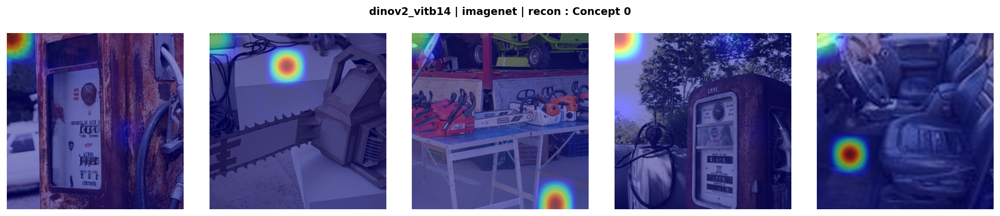

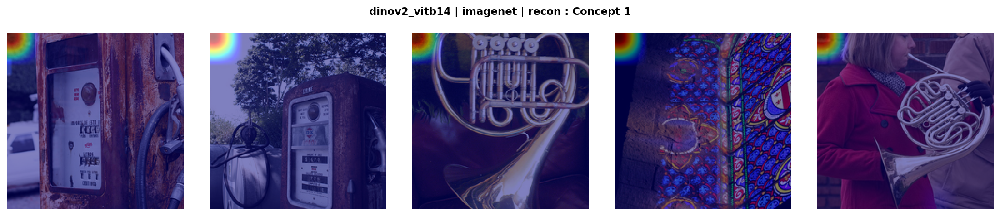

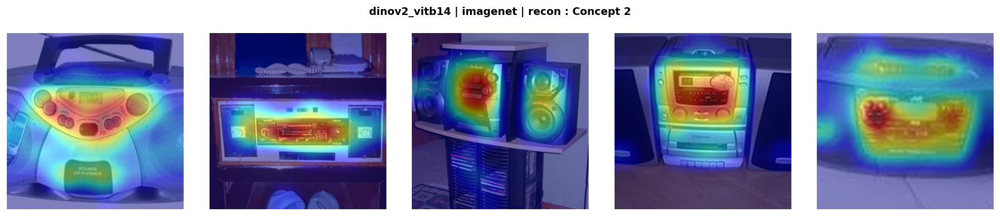

  Saved: output/unsupervised/dinov2_vitb14_imagenet_gram/concept_concept00.png
  Saved: output/unsupervised/dinov2_vitb14_imagenet_gram/concept_concept68.png
  Saved: output/unsupervised/dinov2_vitb14_imagenet_gram/concept_concept31.png
  Saved: output/unsupervised/dinov2_vitb14_imagenet_gram/concept_concept22.png
  Saved: output/unsupervised/dinov2_vitb14_imagenet_gram/concept_concept04.png
  Saved: output/unsupervised/dinov2_vitb14_imagenet_gram/concept_concept18.png
  Saved: output/unsupervised/dinov2_vitb14_imagenet_gram/concept_concept09.png
  Saved: output/unsupervised/dinov2_vitb14_imagenet_gram/concept_concept51.png
  Saved: output/unsupervised/dinov2_vitb14_imagenet_gram/concept_concept03.png
  Saved: output/unsupervised/dinov2_vitb14_imagenet_gram/concept_concept05.png
  Saved: output/unsupervised/dinov2_vitb14_imagenet_gram/concept_concept86.png
  Saved: output/unsupervised/dinov2_vitb14_imagenet_gram/concept_concept10.png
  Saved: output/unsupervised/dinov2_vitb14_imagenet_

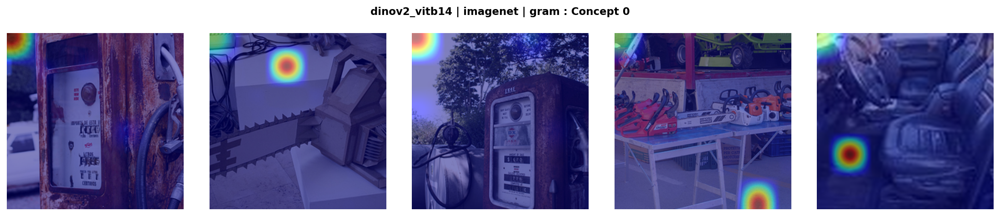

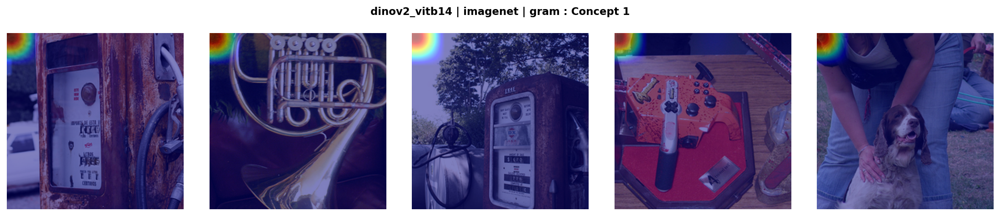

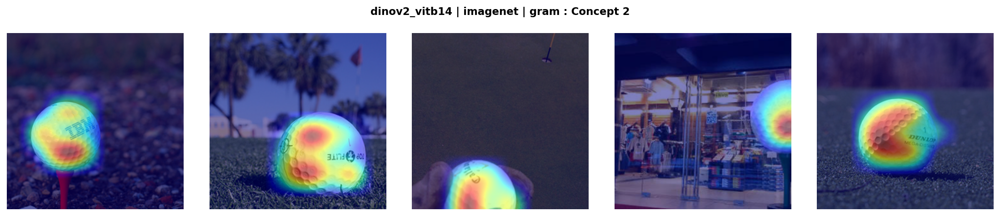

  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_recon/concept_concept00.png
  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_recon/concept_concept04.png
  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_recon/concept_concept05.png
  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_recon/concept_concept10.png
  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_recon/concept_concept08.png
  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_recon/concept_concept76.png
  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_recon/concept_concept54.png
  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_recon/concept_concept07.png
  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_recon/concept_concept09.png
  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_recon/concept_concept45.png
  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_recon/concept_concept20.png

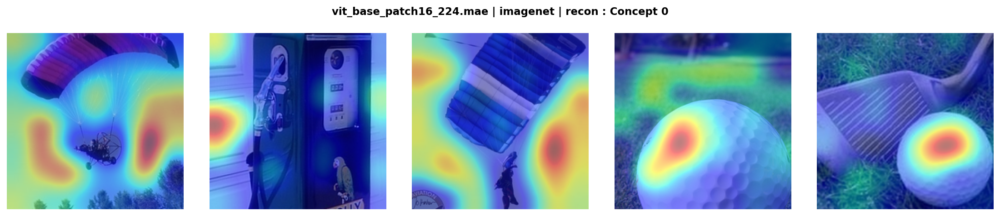

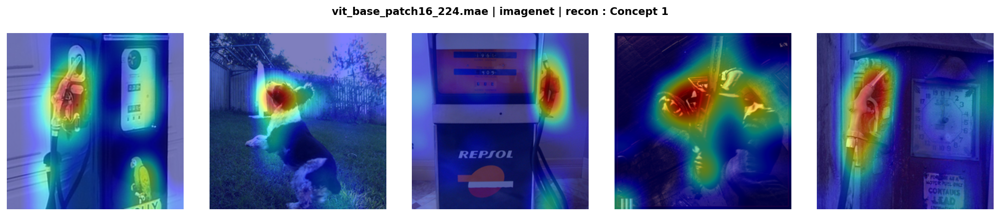

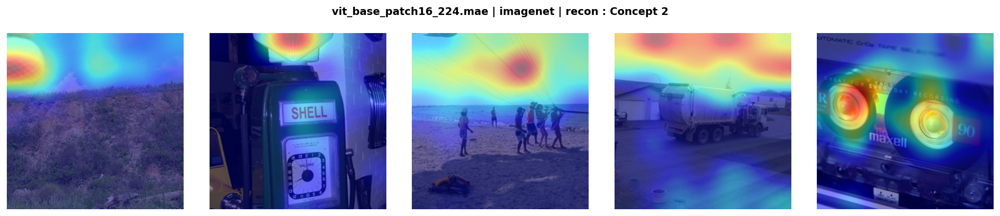

  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_gram/concept_concept00.png
  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_gram/concept_concept04.png
  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_gram/concept_concept08.png
  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_gram/concept_concept11.png
  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_gram/concept_concept05.png
  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_gram/concept_concept01.png
  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_gram/concept_concept19.png
  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_gram/concept_concept10.png
  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_gram/concept_concept22.png
  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_gram/concept_concept25.png
  Saved: output/unsupervised/vit_base_patch16_224.mae_imagenet_gram/concept_concept14.png
  Saved: o

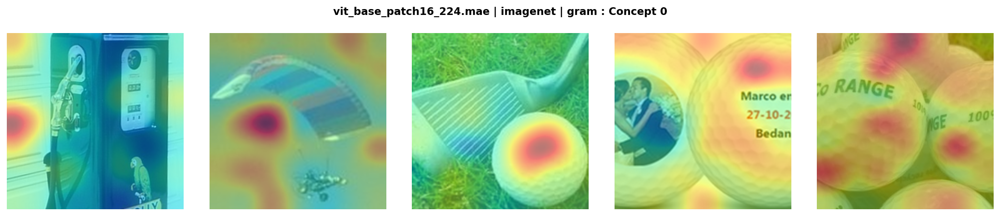

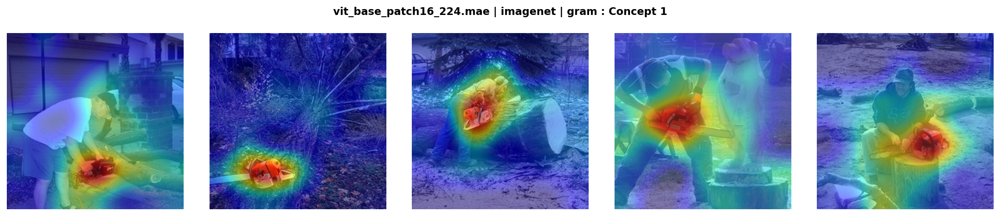

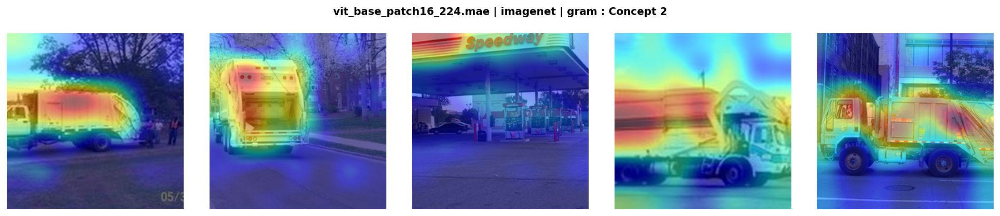

In [18]:
# --- What to visualise -------------------------------------------------------
VIZ_GRID   = [(fam, name, "imagenet") for (fam, name) in BACKBONES]  # (family, model, source)
VIZ_BANKS  = ["recon", "gram"]     # loss variants to contrast (add "kl" for the supervised bank)
VIZ_SEED   = SEED_START            # which saved seed to visualise
VIZ_N_CONCEPTS = RANK              # visualise ALL concepts in the bank, not just the top few
VIZ_TOP_K      = 5                 # images shown per concept (its most strongly activated ones)
VIZ_SHOW       = 3                 # figures displayed inline per bank (None = all of them); all are saved
SAVE_ROOT = OUT_DIR / "unsupervised"

def _reload_pooled_images(source):
    """Return the pooled images, preprocessed, in the exact order that produced the banks.

    Preprocessing is backbone-independent, so this depends only on the source.
    """
    files = _discover(str(DATA_DIR), source, VARIANT, restrict_coco=True)
    chunks, _ = _load_pooled(files, MAX_IMAGES_PER_CLASS, None, pool_seed=POOL_SEED)
    tfm = transforms.Compose([
        transforms.ToPILImage(),
        transforms.Resize(PREPROCESS["resize"]),
        transforms.CenterCrop(PREPROCESS["center_crop"]),
        transforms.ToTensor(),
        transforms.Normalize(PREPROCESS["normalize_mean"], PREPROCESS["normalize_std"]),
    ])
    imgs = np.concatenate(chunks, axis=0)
    return torch.stack([tfm(im) for im in imgs], dim=0).cpu().numpy()

def _n_per_image(model_name, source):
    """Number of (grouped) patch tokens per image, read from the cached token pool."""
    tok = np.load(BANKS_DIR / "gram_pooled" / f"{model_name}_L{EXTRACT_LAYER}_r{RANK}"
                  / "tokens" / f"{source}_all_{VARIANT}.npz", allow_pickle=False)
    return int(tok["patch_tokens"].shape[1])

_img_cache = {}   # reuse the reloaded images across backbones that share a source
for fam, model_name, source in VIZ_GRID:
    if source not in _img_cache:
        _img_cache[source] = _reload_pooled_images(source)
    images_pre_np = _img_cache[source]
    n_per_image = _n_per_image(model_name, source)
    grid_size = int(round(math.sqrt(n_per_image)))       # tokens sit on a square grid
    for bank in VIZ_BANKS:
        bp = (BANKS_DIR / "gram_pooled" / f"{model_name}_L{EXTRACT_LAYER}_r{RANK}"
              / f"{source}_all" / VARIANT / f"{bank}_seed{VIZ_SEED}.npz")
        if not bp.exists():
            print(f"  [skip] {bp.name} not found"); continue
        U = load_bank(str(bp))["U"]
        out_dir = SAVE_ROOT / f"{model_name}_{source}_{bank}"
        out_dir.mkdir(parents=True, exist_ok=True)
        show_concept_heatmaps(images_pre_np, U, n_per_image, grid_size,
                              n_concepts=VIZ_N_CONCEPTS, top_k=VIZ_TOP_K,
                              title=f"{model_name} | {source} | {bank}",
                              save_path=str(out_dir / "concept"))
        # show_concept_heatmaps writes "<save_path>_concept<NN>.png"; tidy that to concept<NN>.png.
        for p in out_dir.glob("concept_concept*.png"):
            p.rename(out_dir / p.name.replace("concept_concept", "concept"))
        pngs = sorted(out_dir.glob("concept*.png"))
        print(f"  {model_name} | {source} | {bank}: saved {len(pngs)} overlays to {out_dir}")
        shown = pngs if VIZ_SHOW is None else pngs[:VIZ_SHOW]
        for png in shown:
            display(Image(filename=str(png)))

## Section G. Tables R1 to R3

All tables in one place. With `WRITE_TABLES_MD = True` they are also written to a markdown file.

In [19]:
print("=" * 30, "TABLE R1 (DINOv2)", "=" * 30);  display(r1_table("dinov2_vitb14"))
print("=" * 30, "TABLE R1 (ViT-MAE)", "=" * 30); display(r1_table("vit_base_patch16_224.mae"))
print("=" * 30, "TABLE R2 (significance)", "=" * 24); display(r2_table())
print("=" * 30, "TABLE R3 (W-Stab DINOv2)", "=" * 22); display(wstab("dinov2_vitb14"))
print("=" * 30, "TABLE R3 (W-Stab ViT-MAE)", "=" * 21); display(wstab("vit_base_patch16_224.mae"))

# Optionally write the tables to a markdown file as well.
if WRITE_TABLES_MD:
    md_path = REPO_ROOT / "results" / "TABLES_from_notebook.md"
    with open(md_path, "w", encoding="utf-8") as f:
        f.write("# Task-agnostic tables (regenerated from the notebook)\n\n")
        for name, tbl in [("R1 DINOv2", r1_table("dinov2_vitb14")),
                          ("R1 ViT-MAE", r1_table("vit_base_patch16_224.mae")),
                          ("R2 significance", r2_table()),
                          ("R3 W-Stab DINOv2", wstab("dinov2_vitb14")),
                          ("R3 W-Stab ViT-MAE", wstab("vit_base_patch16_224.mae"))]:
            f.write(f"## {name}\n\n{tbl.to_markdown(index=False)}\n\n")
    print(f"Wrote {md_path}")

============================== TABLE R1 (DINOv2) ==============================


,Dataset,Method,MSE,C-Gini,d_KL,Gram loss
0,imagenet,PLACE (recon),0.1280 ± 0.0009,0.9874 ± 0.0001,4.3573 ± 0.1326,0.0027 ± 0.0004
1,imagenet,PLACE (+Gram),0.1351 ± 0.0023,0.9847 ± 0.0029,4.9028 ± 0.0821,0.0014 ± 0.0003
2,imagenet,PLACE (+KL),0.1233 ± 0.0025,0.9608 ± 0.0039,0.0709 ± 0.0134,0.0064 ± 0.0010
3,imagenet,SAE (vanilla),0.0764 ± 0.0000,0.9137 ± 0.0031,0.7983 ± 0.0211,0.0008 ± 0.0001
4,imagenet,SAE (gated),0.0672 ± 0.0001,0.8684 ± 0.0094,0.5525 ± 0.0062,0.0001 ± 0.0000
5,coco,PLACE (recon),0.1068 ± 0.0007,0.9820 ± 0.0005,0.1250 ± 0.0101,0.0009 ± 0.0001
6,coco,PLACE (+Gram),0.1119 ± 0.0024,0.9783 ± 0.0044,0.3260 ± 0.0423,0.0007 ± 0.0001
7,coco,PLACE (+KL),0.1105 ± 0.0027,0.9707 ± 0.0071,0.0026 ± 0.0018,0.0022 ± 0.0005
8,coco,SAE (vanilla),0.0752 ± 0.0001,0.9180 ± 0.0045,0.0620 ± 0.0017,0.0008 ± 0.0001
9,coco,SAE (gated),0.0654 ± 0.0001,0.8741 ± 0.0071,0.0480 ± 0.0010,0.0001 ± 0.0000


============================== TABLE R1 (ViT-MAE) ==============================


,Dataset,Method,MSE,C-Gini,d_KL,Gram loss
0,imagenet,PLACE (recon),0.9653 ± 0.0008,0.5110 ± 0.0086,0.4667 ± 0.0048,0.0052 ± 0.0001
1,imagenet,PLACE (+Gram),0.9864 ± 0.0057,0.8061 ± 0.0106,0.4293 ± 0.0135,0.0052 ± 0.0004
2,imagenet,PLACE (+KL),0.9978 ± 0.0047,0.7940 ± 0.0075,0.0315 ± 0.0017,0.0083 ± 0.0008
3,imagenet,SAE (vanilla),0.5472 ± 0.0007,0.4255 ± 0.0059,0.5448 ± 0.0076,0.0026 ± 0.0001
4,imagenet,SAE (gated),0.5230 ± 0.0096,0.5578 ± 0.0138,0.5296 ± 0.0184,0.0006 ± 0.0000
5,coco,PLACE (recon),0.5447 ± 0.0010,0.5425 ± 0.0073,0.0704 ± 0.0012,0.0024 ± 0.0001
6,coco,PLACE (+Gram),0.5692 ± 0.0092,0.7733 ± 0.0056,0.0744 ± 0.0019,0.0031 ± 0.0006
7,coco,PLACE (+KL),0.5851 ± 0.0165,0.7704 ± 0.0070,0.0044 ± 0.0005,0.0047 ± 0.0012
8,coco,SAE (vanilla),0.5008 ± 0.0009,0.4436 ± 0.0109,0.0666 ± 0.0011,0.0029 ± 0.0001
9,coco,SAE (gated),0.4871 ± 0.0116,0.5542 ± 0.0173,0.0698 ± 0.0020,0.0007 ± 0.0000


============================== TABLE R2 (significance) ========================


,Backbone,Dataset,Metric,recon,+Gram,delta,p (Holm)
0,DINOv2,imagenet,C-Gini,0.987 ± 0.000,0.985 ± 0.003,-0.003,0.0001
1,DINOv2,imagenet,MCS,0.262 ± 0.019,0.386 ± 0.078,+0.124,<0.0001
2,DINOv2,imagenet,CMCS (ridge),0.471 ± 0.014,0.505 ± 0.029,+0.034,0.0001
3,DINOv2,coco,C-Gini,0.982 ± 0.001,0.978 ± 0.004,-0.004,0.0034
4,DINOv2,coco,MCS,0.312 ± 0.016,0.521 ± 0.063,+0.209,<0.0001
5,DINOv2,coco,CMCS (ridge),0.348 ± 0.015,0.365 ± 0.021,+0.017,0.0018
6,ViT-MAE,imagenet,C-Gini,0.511 ± 0.009,0.806 ± 0.011,+0.295,<0.0001
7,ViT-MAE,imagenet,MCS,0.419 ± 0.008,0.971 ± 0.003,+0.552,<0.0001
8,ViT-MAE,imagenet,CMCS (ridge),0.781 ± 0.004,0.754 ± 0.004,-0.027,<0.0001
9,ViT-MAE,coco,C-Gini,0.543 ± 0.007,0.773 ± 0.006,+0.231,<0.0001


============================== TABLE R3 (W-Stab DINOv2) ======================


,Dataset,PLACE (recon),PLACE (+Gram),PLACE (+KL),SAE (vanilla),SAE (gated)
0,imagenet,0.8129 ± 0.0276,0.8714 ± 0.0279,0.9001 ± 0.0128,0.9077 ± 0.0164,0.8007 ± 0.0228
1,coco,0.7272 ± 0.0297,0.8326 ± 0.0244,0.8566 ± 0.0136,0.9114 ± 0.0178,0.7750 ± 0.0198


============================== TABLE R3 (W-Stab ViT-MAE) =====================


,Dataset,PLACE (recon),PLACE (+Gram),PLACE (+KL),SAE (vanilla),SAE (gated)
0,imagenet,0.8539 ± 0.0125,0.8807 ± 0.0130,0.8855 ± 0.0118,0.8914 ± 0.0223,0.4418 ± 0.0161
1,coco,0.7473 ± 0.0191,0.8652 ± 0.0178,0.8658 ± 0.0193,0.8616 ± 0.0225,0.4142 ± 0.0164


### Results

- MCS with the `kl` bank increases with the Gram loss in all four settings: +0.124 and +0.209 on
  DINOv2 (ImageNet, COCO), +0.552 and +0.413 on ViT-MAE (all p < 10⁻⁴).
- CMCS increases on DINOv2 (+0.034, +0.017), decreases on ViT-MAE ImageNet (−0.027) and is unchanged
  on ViT-MAE COCO (p = 0.82).
- C-Gini: on DINOv2 all three PLACE banks are above both SAEs (0.96 to 0.99 against 0.87 to 0.92).
  On ViT-MAE, `gram` and `kl` are above both SAEs, while `recon` (0.51 to 0.54) is in the SAE range
  (0.43 to 0.56).
- W-Stab: `gram` is higher than `recon` in all four settings (0.813 → 0.871, 0.727 → 0.833,
  0.854 → 0.881, 0.747 → 0.865) and close to `kl`.
- SAEs have lower MSE in all four settings and lower d_KL in three. On DINOv2 the Gram loss increases
  d_KL over reconstruction (4.357 → 4.903 on ImageNet, 0.125 → 0.326 on COCO).
- Qualitatively, `gram` concepts are better localized than `recon` concepts on the same images.

Small differences from the paper come from seed noise and from the Gram error being estimated on a
random subset of 2,048 tokens.